In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from scipy.optimize import curve_fit
from scipy.signal import resample
from astropy.io import fits
from astropy.table import Table
from astropy.table import vstack
from scipy.stats import ttest_rel
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from mpl_toolkits.axes_grid1 import make_axes_locatable
from matplotlib.ticker import AutoMinorLocator
import os
import h5py
import emcee
import corner

FIG_DIR = "/raid/scratch/work/alberttg/Masters_project/Plots"

DATA_PRODUCTS_PATH = "/raid/scratch/work/alberttg/Masters_project/Data_products"

POSTERIOR_PATH = '/raid/scratch/work/austind/GALFIND_WORK/Bagpipes/pipes/posterior'

In [2]:
def weighted_reduced_chi_squared(y_obs, y_err_low, y_err_high, y_model, n_params,
                                  x_obs=None, x_err_low=None, x_err_high=None,
                                  gradient=None):
    """
    Calculate the reduced chi-squared for data with asymmetric uncertainties,
    optionally including x uncertainties projected onto y via the model gradient.

    Parameters
    ----------
    y_obs : array_like
        Observed y values.
    y_err_low : array_like
        Lower (negative) uncertainties on y.
    y_err_high : array_like
        Upper (positive) uncertainties on y.
    y_model : array_like
        Model predictions.
    n_params : int
        Number of fitted parameters.
    x_obs : array_like, optional
        Observed x values. Required if x_err_low/x_err_high are given.
    x_err_low : array_like, optional
        Lower (negative) uncertainties on x. If None, treated as zero.
    x_err_high : array_like, optional
        Upper (positive) uncertainties on x. If None, treated as zero.
    gradient : float, optional
        Local gradient of the model (dy/dx), used to project x uncertainty
        onto y. Required if x uncertainties are non-zero.

    Returns
    -------
    chi2_red : float
        Reduced chi-squared.
    """

    y_obs = np.asarray(y_obs, dtype=float)
    y_model = np.asarray(y_model, dtype=float)
    y_err_low = np.asarray(y_err_low, dtype=float)
    y_err_high = np.asarray(y_err_high, dtype=float)

    # Use the appropriate uncertainty depending on which side of the data
    sigma_y = np.where(y_model > y_obs, y_err_high, y_err_low)

    # Handle x uncertainties, if provided
    if x_err_low is None:
        x_err_low = np.zeros_like(y_obs)
    else:
        x_err_low = np.asarray(x_err_low, dtype=float)

    if x_err_high is None:
        x_err_high = np.zeros_like(y_obs)
    else:
        x_err_high = np.asarray(x_err_high, dtype=float)

    # If x errors are all zero, skip the x-error projection entirely —
    # this avoids requiring x_obs/gradient when there's nothing to project
    if np.all(x_err_low == 0) and np.all(x_err_high == 0):
        sigma = sigma_y
    else:
        if x_obs is None or gradient is None:
            raise ValueError("x_obs and gradient must be provided when x uncertainties are non-zero.")

        x_obs = np.asarray(x_obs, dtype=float)
        sigma_x = np.where(y_model > y_obs, x_err_high, x_err_low)

        # project x uncertainty onto y using the model gradient, combine in quadrature
        sigma = np.sqrt(sigma_y**2 + (gradient * sigma_x)**2)

    chi2 = np.sum(((y_obs - y_model) / sigma) ** 2)

    dof = len(y_obs) - n_params
    if dof <= 0:
        raise ValueError("Degrees of freedom must be positive.")

    chi2_red = chi2 / dof

    return chi2_red

In [3]:
def gaussian_function(x, sigma, mu, amp):
    """
    1D Gaussian for a histogram density plot. The amplitude is dependent on sigma.
    """
    # amp = 1 / (sigma * np.sqrt(2 * np.pi))

    y = amp * np.exp( - ((x - mu)**2) / (2 * sigma**2) )

    return y

In [4]:
def _parse_err(err, n):
    """
    Normalize an error specification into (err_lo, err_hi) arrays of length n.

    Accepted forms for `err`:
      - None                            -> zeros (no error)
      - scalar or 1D array of length n  -> symmetric error (same as before)
      - [err_high, err_low]             -> asymmetric error; each of
        err_high/err_low can be a scalar (applied to all points) or a
        length-n array (per-point)

    Returned lo/hi are positive distances from the central value
    (lower bound = value - lo, upper bound = value + hi).
    """
    if err is None:
        return np.zeros(n), np.zeros(n)

    # Asymmetric: [err_high, err_low]
    if isinstance(err, (list, tuple)) and len(err) == 2:
        hi = np.asarray(err[0], dtype=float) 
        lo = np.asarray(err[1], dtype=float)
        if hi.ndim == 0:
            hi = np.full(n, float(hi))
        if lo.ndim == 0:
            lo = np.full(n, float(lo))
        return lo.copy(), hi.copy()

    # Symmetric: scalar or array, same as before
    arr = np.asarray(err, dtype=float)
    if arr.ndim == 0:
        arr = np.full(n, float(arr))
    return arr.copy(), arr.copy()


def fit_gaussian_mcmc(corner_path, posterior_sum, x_in, y_in, x_err=None, y_err=None, x_pivot=None,
                     n_walkers=32, n_steps=5000, plot=True, save_path=None):
    """
    Bayesian gaussian fit without intrinsic scatter,
    supporting asymmetric measurement errors in both x and y (but we have none here).

    x_err / y_err each accept:
      - None, a scalar, or a 1D array of length N (symmetric errors, same
        as before), OR
      - [err_high, err_low] for asymmetric errors, where each of
        err_high/err_low is a scalar (applied to every point) or a
        length-N array (per-point).

    Asymmetric-error handling
    --------------------------
    Each data point's error distribution is modeled as a split-normal
    (two-piece Gaussian): width `sigma_lo` below the measured value and
    `sigma_hi` above it. At every MCMC step, for each point we compare the
    model prediction to the data (delta = model - data) and pick the
    error side consistent with that comparison:
        delta >= 0  ->  use the "hi" error (model sits above the data)
        delta <  0  ->  use the "lo" error (model sits below the data)
    This is applied to both the y errors and the x errors (the latter
    projected into y-space via the slope, m^2 * xerr^2, as in the
    symmetric case). This is the standard practical approximation for
    asymmetric errors in a likelihood — it is exact only when the true
    error distribution really is split-normal, but works well in general
    and reduces to the ordinary symmetric-error likelihood when lo == hi.
    The intrinsic scatter term sigma_int is kept symmetric.
    """
    # --- Step 1: Data Cleaning & Pivot Handling ---
    x = np.asarray(x_in, dtype=float)
    y = np.asarray(y_in, dtype=float)
    n = len(x)

    xe_lo, xe_hi = _parse_err(x_err, n)
    ye_lo, ye_hi = _parse_err(y_err, n)
    # xe_lo = np.zeros(n)
    # xe_hi = np.zeros(n)
    # ye_lo = np.zeros(n)
    # ye_hi = np.zeros(n)
    # My basic version of _parse_err function 

    xp = 0.0 if x_pivot is None else x_pivot
    
    mask = (
        np.isfinite(x) & np.isfinite(y)
        & np.isfinite(xe_lo) & np.isfinite(xe_hi)
        & np.isfinite(ye_lo) & np.isfinite(ye_hi)
    )

    x, y = x[mask], y[mask]
    xe_lo, xe_hi = xe_lo[mask], xe_hi[mask]
    ye_lo, ye_hi = ye_lo[mask], ye_hi[mask]
    n = len(x)

    # Guard against zero/negative error entries (keeps likelihood well-defined)
    xe_lo = np.where(xe_lo <= 0, 1e-10, xe_lo)
    xe_hi = np.where(xe_hi <= 0, 1e-10, xe_hi)
    ye_lo = np.where(ye_lo <= 0, 1e-10, ye_lo)
    ye_hi = np.where(ye_hi <= 0, 1e-10, ye_hi)

    #print(xe_lo)
    #print(xe_hi)
    #print(ye_lo)
    #print(ye_hi)

    if len(x) < 2:
        raise ValueError("Not enough finite data points.")

    # --- Step 2: Robust Initial Guess ---
    try:
        popt, pcov = curve_fit(gaussian_function, x - xp, y, p0=[np.std(x-xp), np.mean(x-xp), np.max(y)], bounds=([1e-5, -np.inf, 0], [10.0, np.inf, np.inf]))
        guess_sig, guess_mu, guess_amp = popt
        guess_sig = np.abs(guess_sig)
        print(f"Guesses: sig = {guess_sig:.3f}, mean = {guess_mu:.3f}, amplitude = {guess_amp:.3f}")
    
    except np.linalg.LinAlgError:
        guess_sig, guess_mu, guess_amp = np.std(x-xp), np.mean(x-xp), np.max(y)

    # guess_std = np.std(y - gaussian_function(x-xp, guess_sig, guess_mu, guess_amp))

    # --- Step 3: MCMC Functions (3 parameters: m, c, sigma_int) ---
    def log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        sig, mu, amp = theta
        # if sigma_int <= 0: this was one of the params
        #    return -np.inf

        model = gaussian_function((x-xp), sig, mu, amp)
        # delta = model - y  # positive => model above data

        delta = x - xp

        y_err = np.where(delta >= 0, yerr_hi, yerr_lo)
        x_err = np.where(delta >= 0, xerr_hi, xerr_lo)

        n = len(x) # no. of data points

        ln_L = -0.5 * np.sum(np.log(2 * np.pi * y_err**2)) - 0.5 * np.sum(((y - model) / y_err)**2)
        # ln_L = - (n/2) * np.log(2*np.pi) - n * np.log(sig) - 0.5 * np.sum( ((delta - mu)  / sig)**2)

        return ln_L

    # Set prior limits safely outside empirical distribution boundaries
    min_sig, max_sig = 1e-4, guess_sig * 3.0
    min_mu, max_mu = guess_mu - (3 * guess_sig), guess_mu + (3 * guess_sig)
    min_amp, max_amp = 0.4 * guess_amp, 1.5 * guess_amp # Maybe check these ------------

    def log_prior(theta): 
        """
        Uses Jeffrey's prior (log-uniform) instead of flat uniform prior.
        """
        sig, mu, amp = theta
        if min_sig < sig < max_sig and min_mu < mu < max_mu and min_amp < amp < max_amp:
            return 0 # This is return 0 for flat uniform prior
        return -np.inf

    def log_probability(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp):
        lp = log_prior(theta)
        if not np.isfinite(lp):
            return -np.inf
        ll = log_likelihood(theta, x, y, xerr_lo, xerr_hi, yerr_lo, yerr_hi, xp)
        return lp + ll if np.isfinite(ll) else -np.inf

    # --- Step 4: Run MCMC ---
    ndim = 3
    # initial = np.array([guess_sig, guess_mu, guess_amp if guess_std > 0 else 0.1]) old
    initial = np.array([guess_sig, guess_mu, guess_amp])
    pos = initial + 1e-4 * np.random.randn(n_walkers, ndim)

    sampler = emcee.EnsembleSampler(
        n_walkers, ndim, log_probability,
        args=(x, y, xe_lo, xe_hi, ye_lo, ye_hi, xp)
    )
    sampler.run_mcmc(pos, n_steps, progress=True)

    flat_samples = sampler.get_chain(discard=1000, thin=15, flat=True)

    x_range = np.linspace(x.min(), x.max(), 100)
    sig_samples = flat_samples[:, 0]
    mu_samples = flat_samples[:, 1]
    amp_samples = flat_samples[:, 2]
    # ------------------------------------------------------ intrinsic scatter was a parameter here but we are fitting to a histogram

    models = gaussian_function((x_range - xp), sig_samples[:, np.newaxis], mu_samples[:, np.newaxis], amp_samples[:, np.newaxis])

    sig_med, mu_med, amp_med = np.median(flat_samples, axis=0)
    lower_bound = np.percentile(models, 16, axis=0)
    upper_bound = np.percentile(models, 84, axis=0)

    # --- Step 5: Visualization ---
    if plot:
        """
        plt.figure(figsize=(8, 6))
        print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")

        # matplotlib expects asymmetric errors as [lower_distances, upper_distances]
        # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
        
        plt.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
        plt.plot(x_range, gaussian_function((x_range - xp), sig_med, mu_med, amp_med), color="darkblue", lw=2, label="Median Fit")
        plt.legend()
        if save_path:
            plt.savefig(save_path, dpi=150, bbox_inches="tight")
        plt.show()
        """

        labels = [r"Sigma $\sigma$", f"Mean $\mu$ (at $x={xp}$)", "Amplitude"]
        corner.corner(flat_samples, labels=labels, truths=[sig_med, mu_med, amp_med], show_titles=True)
        plt.savefig(corner_path, dpi=150)
        plt.show()

    sig_16 = np.percentile(flat_samples[:, 0], 16)
    sig_84 = np.percentile(flat_samples[:, 0], 84)

    fwhm_med = np.sqrt(8 * np.log(2)) * sig_med
    fwhm_upp_err = np.sqrt(8 * np.log(2)) * (sig_84 - sig_med)
    fwhm_low_err = np.sqrt(8 * np.log(2)) * (sig_med - sig_16)

    red_chi2 = weighted_reduced_chi_squared(y_obs=y, y_err_low=ye_lo, y_err_high=ye_hi, 
                                            y_model=gaussian_function((x-xp), sig_med, mu_med, amp_med), 
                                            n_params=3,
                                            x_obs=None, x_err_low=None, x_err_high=None,
                                            gradient=None)
    print(f"Reduced chi squared = {red_chi2:.3f}")

    results = {
        "sigma_median": sig_med,
        "mean_median": mu_med,
        "amplitude": amp_med,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound,
        "sig_16": np.percentile(flat_samples[:, 0], 16),
        "sig_84": np.percentile(flat_samples[:, 0], 84),
        "mu_16": np.percentile(flat_samples[:, 1], 16),
        "mu_84": np.percentile(flat_samples[:, 1], 84),
        "amp_16": np.percentile(flat_samples[:, 2], 16),
        "amp_84": np.percentile(flat_samples[:, 2], 84),
        "x_pivot": xp,
        "x_range": x_range,
        "fwhm": fwhm_med,
        "fwhm_upper_error": fwhm_upp_err,
        "fwhm_lower_error": fwhm_low_err,
        "reduced_chi_squared": red_chi2,
        "centres": x,
        "counts": y,
        "yerr": ye_hi,
        "posterior_sum": posterior_sum,
    }

    return results

In [5]:
def get_posterior(sample_table, SFH_model, refit=False):
    """
    Finding the paths to the stellar mass posterior, based on galaxy survey id, survey and SFH model used in BAGPIPES.
    Each galaxy has its own posterior.
    """

    surveys = np.asarray(sample_table["SURVEY"].data, dtype=str)

    survey_ids = np.asarray(sample_table["#ID"].data, dtype=int)

    redshifts = np.asarray(sample_table["input_redshift"].data, dtype=float)

    mass = np.asarray(sample_table["stellar_mass_50"].data, dtype=float)

    src_corr = np.asarray(sample_table["ext_src_corr_0.32as_F444W"].data, dtype=float)

    posteriors = []

    for i in range(len(sample_table)):

        gal_id = survey_ids[i]
        survey = surveys[i]
        redshift = redshifts[i]
        corr = src_corr[i]

        if survey in ["CEERSP1", "CEERSP2", "CEERSP3", "CEERSP4", "CEERSP5", "CEERSP6", "CEERSP7", "CEERSP8", "CEERSP9", "CEERSP10", "NEP-1", "NEP-2", "NEP-3", "NEP-4", "NGDEEP"]:

            path = os.path.join(POSTERIOR_PATH, f"v14_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")

        elif survey in ["PRIMER-COSMOS","PRIMER-UDS"]:
                
            path = os.path.join(POSTERIOR_PATH, f"v12_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")


        elif survey in ["JADES-DR3-GS-East", "JADES-DR3-GS-North", "JADES-DR3-GS-South", "JADES-DR3-GS-West", "JADES-DR3-GN-Parallel", "JADES-DR3-GN-Medium", "JADES-DR3-GN-Deep"]:

            path = os.path.join(POSTERIOR_PATH, f"v13_psfmatch_F444W_empirical/{survey}/ACS_WFC+NIRCam/0.32as/{SFH_model}/{gal_id}.h5")
            
        else:
            print(f"Galaxy {gal_id} could not be found in these surveys")
            print(f"Check survey {survey}")
            continue


        with h5py.File(path,'r') as hf:
            # Print all root level object names (aka keys) 
            # these can be group or dataset names 
            # print("Keys: %s" % hf['basic_quantities'].keys())
            # print("Keys: %s" % hf['advanced_quantities'].keys())
            stellar_mass = hf['basic_quantities']['stellar_mass'][:]
            
        stellar_mass = stellar_mass * corr
        median_mass = np.median(stellar_mass)
        log_mass = np.array(stellar_mass - median_mass)

        if len(log_mass) != 500:
            print("Length not 500: ", len(log_mass))
            print(f"Check the posterior of galaxy {gal_id} in survey {survey} ")
            log_mass = resample(x=log_mass, num=500, axis=0)
            print(f"Posterior of galaxy {gal_id} in survey {survey} is resampled")

        posteriors.append(log_mass) # ought to be in same order as mass and redshift are ordered, which is by ith row of sample table

    # print(posteriors)
    
    plot_binned_posterior(mass, redshifts, posteriors, 50, refit=refit) # I think the posterior are in the same order as galaxy table (mass, redshift...)

    

In [6]:
def calculate_hist_data(posterior_sum, histogram_bins):
    """
    Histogram the posterior data into n_bins=histrogram_bins.
    """
    raw_counts, edges = np.histogram(posterior_sum, bins=histogram_bins)
    centres = 0.5 * (edges[1:] + edges[:-1])
    yerr = np.sqrt(np.maximum(raw_counts, 1)) # Poisson errors on hist density

    # Calculate the normalization factor used by density=True
    bin_widths = np.diff(edges)
    total_counts = len(posterior_sum)
    normalization = total_counts * bin_widths

    # Calculate density and its corresponding scaled error
    counts = raw_counts / normalization
    # Apply Poisson error on raw counts, safely handling zero-bins with np.maximum
    yerr = np.sqrt(np.maximum(raw_counts, 1)) / normalization

    return centres, counts, yerr
    

In [7]:
def trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results):
    """
    If the histogram centres data has really long tails and a narrow peak, 
    trim the posterior_sum from which the histogram was initially applied,
    then repeat the histogram and fitting process.
    """
    print(f"Posterior: {np.min(posterior_sum):.3f} -- {np.max(posterior_sum):.3f}, length = {len(posterior_sum)}")

    sig_med = results["sigma_median"]
    mu_med = results["mean_median"]
    print(f"From fit: mean = {mu_med:.3f}, sigma = {sig_med:.3f}")
    print(f"From hist of posterior: mean = {centres[np.argmax(counts)]}")

    n_sig = 5 # how many sigma away from mean within which to recalculate posterior_sum and histogram

    if (np.max(centres) > mu_med + n_sig * sig_med) or (np.min(centres) < mu_med - n_sig * sig_med):

        print("Tails too long, trimming posterior and refitting.")

        trim_mask = (posterior_sum <= mu_med + n_sig * sig_med) & (posterior_sum >= mu_med - n_sig * sig_med)
        posterior_sum = posterior_sum[trim_mask]

        print(f"Posterior: {np.min(posterior_sum):.3f} -- {np.max(posterior_sum):.3f}, length = {len(posterior_sum)}")

        centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins)

        results = fit_gaussian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Lorentzian_corner_plots/corner_{m}_{z}.png"),
                                        posterior_sum,
                                        centres, counts, 
                                        x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

        return results

    else:
        return results

In [ ]:
def plot_binned_posterior(mass, redshift, posterior, histogram_bins, refit=False):
    """
    Sorting the posterior into bins, selected by mass and redshift value.

    mass : array of floats
        The mass values of all the galaxies
    redshift : array of floats
        The zfix redshift values of all the galaxies
    posterior : array of arrays of floats
        The posterior for each galaxy, which are each an array.
    histogram_bins : float
        Number of histogram bins for each plot and also for gaussian fitting
    refit : bool
        User decides whether or not to refit.
    """
    z_bins = [[6.5, 7.5], [7.5, 8.5], [8.5, 9.5], [9.5, 10.5], [10.5, 11.5], [11.5, 13.5]]

    fig, axes = plt.subplots(3, 6, figsize=(35,18), constrained_layout=True)
    # Starting binning, bin by mass first (vertical bins)
    # mass_bins = np.linspace(mass.min(), mass.max(), n_mass_bins + 1)
    # mass_bins = [[mass_bins[i], mass_bins[i + 1]] for i in range(len(mass_bins) - 1)]
    # mass_bins.reverse()
    #print("Mass bins: ", mass_bins)
    mass_bins = [[9.0,11], [8,9.0], [5,8]] # Have put them in reverse for the gridspec plotting

    for i in range(len(mass_bins)):

        bin_width = mass_bins[i][1] - mass_bins[i][0]

        mass_bin_mask = (mass >= mass_bins[i][0]) & (mass < mass_bins[i][1]) # Splitting into mass bins

        redshift_m_binned = redshift[mass_bin_mask]
        mass_errors_m_binned = mass[mass_bin_mask]
        
        posterior_m_binned = [item for item, m in zip(posterior, mass_bin_mask) if m]


        # Now bin by z (horizontal bins)
        for j in range(len(z_bins)):

            z_bin_mask = (redshift_m_binned >= z_bins[j][0]) & (redshift_m_binned < z_bins[j][1])

            redshift_z_binned = redshift_m_binned[z_bin_mask]
            mass_z_binned = mass_errors_m_binned[z_bin_mask] # x axis values now binned by z and mass

            print("m bin: ", mass_bins[i])
            print("z bin: ", z_bins[j])
            print("Number of gals in bin: ", len(redshift_z_binned))

            posterior_z_binned = [item for item, m in zip(posterior_m_binned, z_bin_mask) if m]

            # [print(len(p)) for p in posterior_z_binned] # this checks that most posterior are length 500, but one is 106 and one is 107

            if len(posterior_z_binned) == 0:
                continue  # or leave the axis empty

            # --------------------------------------------- binning complete -----------------------------------------------
            # Now calculating posterior sum and making into a normalised histogram

            posterior_sum = np.concatenate(posterior_z_binned, axis=0)  # was trying this to see combined distribution of mass offsets for the galaxies in a bin
            # posterior_sum = [sum(p) for p in zip(*posterior_z_binned)] # idk about this one...
            # print("sum shape: ", np.shape(posterior_sum))

            # ------------------------------------------------ mcmc fitting ------------------------------------------------
             # Create the HDF5 file
            if i == 0:
                m = "m>9.5"
            if i == 1:
                m = "m=8-9.5" # centre of mass bin
            if i == 2:
                m = "m<8"
            z = f"z={0.5*(z_bins[j][0] + z_bins[j][1])}" # centre of redshift bin
            
            file_path = os.path.join(DATA_PRODUCTS_PATH, "Gridspec_mass_errors", "Gaussian_fit_results", f"results_table_{m}_{z}.h5")
    
            if os.path.exists(file_path) and not refit:
                # Load previously saved fit results
                with h5py.File(file_path, 'r') as hf:
                    results = {key: hf[key][()] for key in hf.keys()}
                print(f"Loaded existing results from {file_path}")

            else:
                centres, counts, yerr = calculate_hist_data(posterior_sum, histogram_bins) # Initial calculation

                results = fit_gaussian_mcmc(os.path.join(FIG_DIR, "Gridspec_mass_errors", f"Gaussian_corner_plots/corner_{m}_{z}.png"),
                                            posterior_sum,
                                            centres, counts, 
                                            x_err=None, y_err=yerr, n_walkers=32, n_steps=5000, plot=True)

                results = trim_and_refit(m, z, centres, counts, yerr, posterior_sum, histogram_bins, results)
                # Refitted if needed to trim data
                with h5py.File(file_path, 'w') as hf:
                    for key, val in results.items():
                        hf.create_dataset(key, data=val)
                print(f"Saved to {file_path}")


            sig_med = results["sigma_median"]
            mu_med = results["mean_median"]
            amp_med = results["amplitude"]
            x_range = results["x_range"]
            x_pivot = results["x_pivot"]
            lower_bound = results["lower_bound"]
            upper_bound = results["upper_bound"]
            fwhm = results["fwhm"]
            centres = results["centres"]
            counts = results["counts"]
            posterior_sum = results["posterior_sum"]

            half_max = amp_med / 2

            left_crossing = centres[np.argmax(counts)] - sig_med # should probably use mu_med but cba
            right_crossing = centres[np.argmax(counts)] + sig_med


            # ---------------------------------------------- Plotting -------------------------------------------
            
            ax = axes[i,j]
                    
            # ax.set_ylabel(r'Probability density \left( $\sigma_{M_\star}^{-1}$ \right)', fontsize=16)
            if j == 0:
                ax.set_ylabel(rf"${mass_bins[i][0]} ≤ \log_{10}(M_\star/M_\odot) < {mass_bins[i][1]}$", fontsize=16)
            
            ax.grid(True)

            print(f"Median sigma: {sig_med:.3f}, mean: {mu_med:.3f}, amplitude: {amp_med:.3f}")
    
            # ax.errorbar(x, y, xerr=[xe_lo, xe_hi], yerr=[ye_lo, ye_hi], fmt=".k", alpha=0.4, label="Data", zorder=1)
            
            ax.fill_between(x_range, lower_bound, upper_bound, color="royalblue", alpha=0.3, label=r"1$\sigma$ Confidence")
            ax.plot(x_range, gaussian_function((x_range - x_pivot), sig_med, mu_med, amp_med), color="darkblue", lw=2, label="Median Fit")
            ax.legend(fontsize=14)

            ax.tick_params(
                    axis="both",
                    which="major",
                    labelsize=14,
                    length=8,
                    width=1.5,
                    direction="in",
                    top=True,
                    right=True
                    )
            
            ax.xaxis.set_minor_locator(AutoMinorLocator(5))
            ax.yaxis.set_minor_locator(AutoMinorLocator(5))

            ax.tick_params(
                    axis="both",
                    which="minor",
                    length=4,
                    width=1,
                    direction="in",
                    top=True,
                    right=True
                    )

            ax.hist(posterior_sum, bins=histogram_bins, color='steelblue', density=True)

            ax.axhline(half_max, color='black', linestyle='--',
                        label='Half maximum')
            
            ax.axvline(x=left_crossing, ymin=0, ymax=0.5, color='red', linestyle=':')
            ax.axvline(right_crossing, ymin=0, ymax=0.5,  color='red', linestyle=':')

            ax.fill_between(
                [left_crossing, right_crossing],
                [0, 0],
                [half_max, half_max],
                alpha=0.3,
                color='red',
                label=f'FWHM = {fwhm:.3f}'
            )

            ax.legend(loc="upper left", fontsize=15)

            ax.set_xlim( (mu_med - 6 * sig_med), (mu_med + 6 * sig_med) )

            legend_text = rf"${z_bins[j][0]} ≤ z < {z_bins[j][1]}$"
            ax.text(0.6, 0.95, legend_text, transform=ax.transAxes, fontsize=15, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))

    fig.supylabel(r'Histogram density', fontsize=20)
    fig.supxlabel(r'Stellar Mass $\log_{10}(M_\star/M_\odot) - \langle( \log_{10}(M_\star/M_\odot) \rangle $', fontsize=20)
    plt.tight_layout()
    fig_path = os.path.join(FIG_DIR, "Gridspec_mass_errors", "gridspec_mass_errors_gaussian.png")
    fig.savefig(fig_path, dpi=300, bbox_inches="tight")
    plt.close(fig)


Length not 500:  106
Check the posterior of galaxy 11825 in survey NEP-4 
Posterior of galaxy 11825 in survey NEP-4 is resampled
Length not 500:  117
Check the posterior of galaxy 96942 in survey PRIMER-UDS 
Posterior of galaxy 96942 in survey PRIMER-UDS is resampled
m bin:  [9.0, 11]
z bin:  [6.5, 7.5]
Number of gals in bin:  50
Guesses: sig = 0.065, mean = -0.002, amplitude = 5.163


100%|██████████| 5000/5000 [00:05<00:00, 864.27it/s]


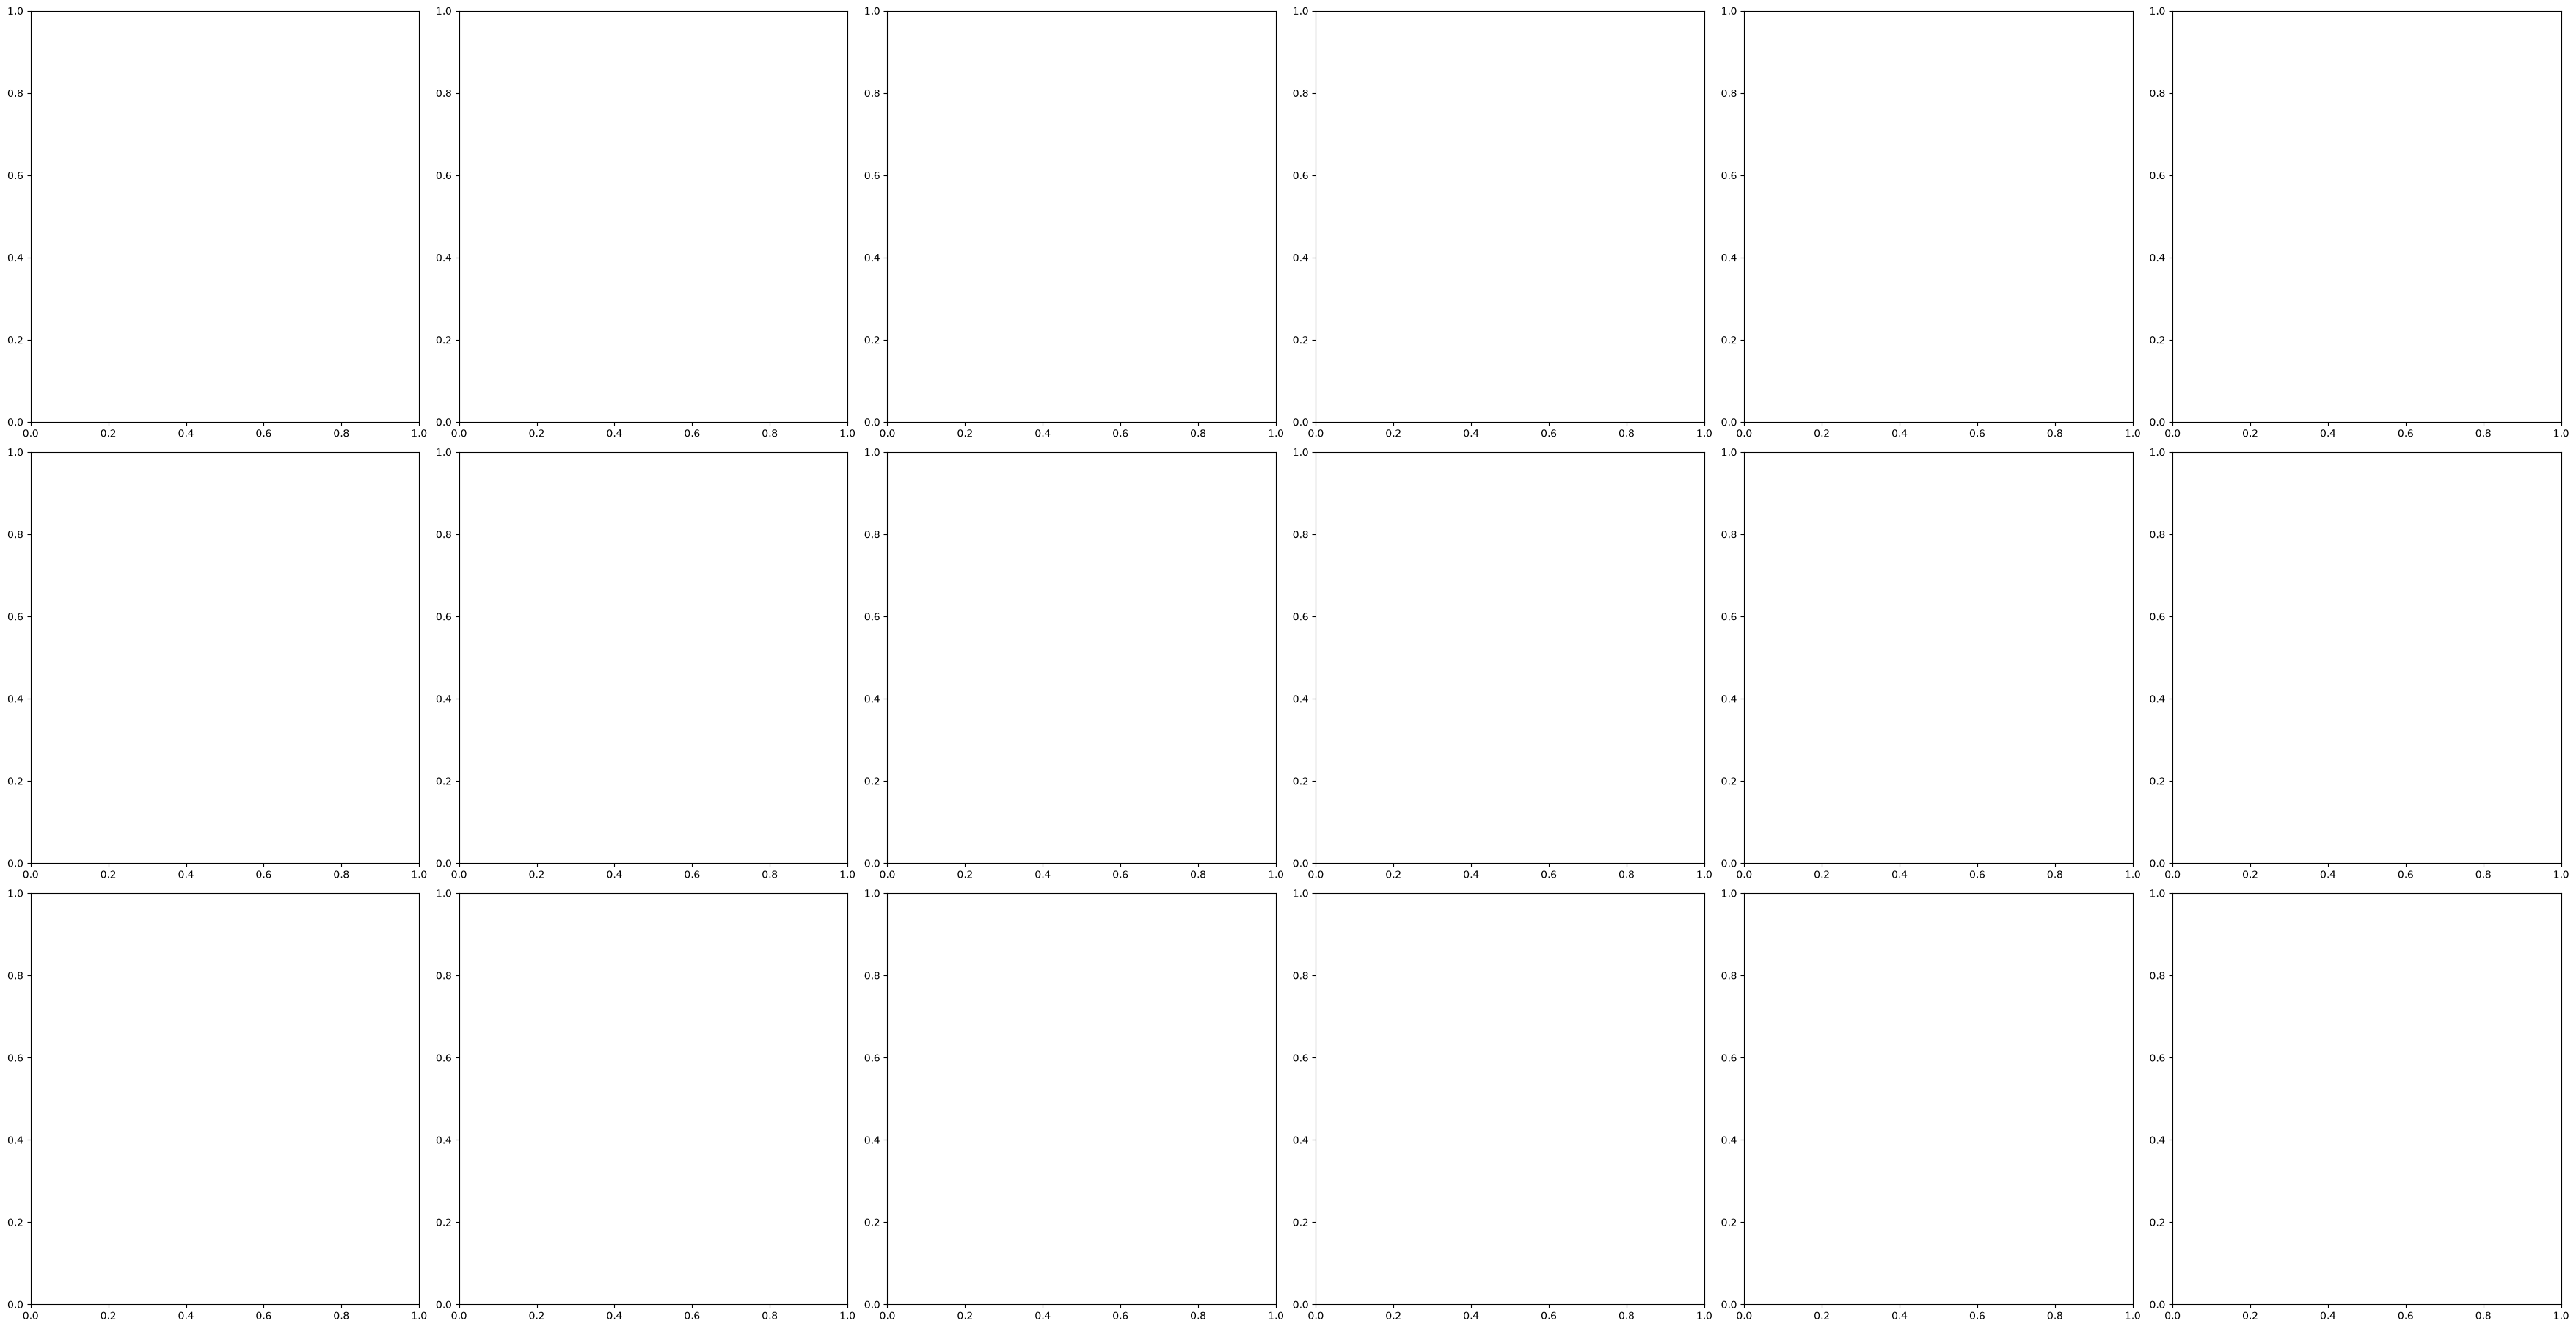

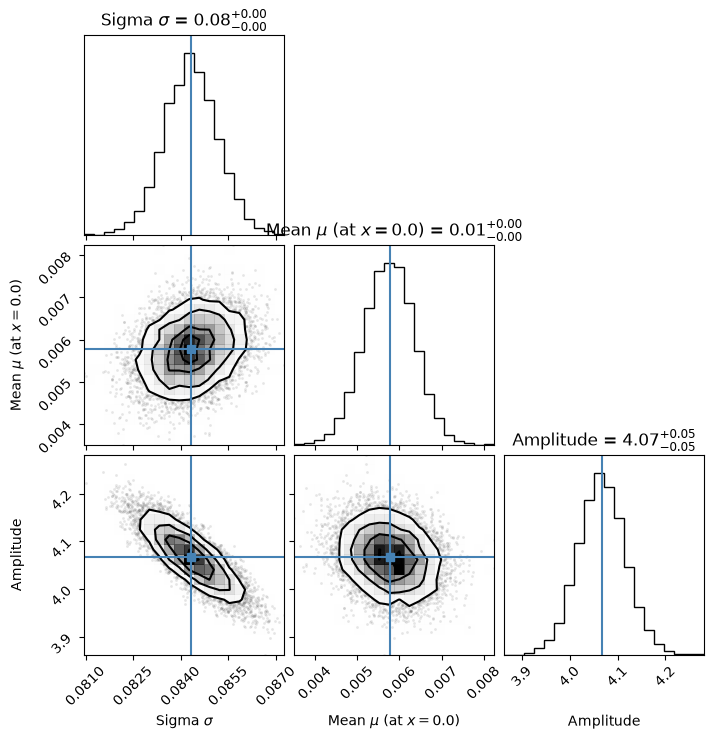

Reduced chi squared = 74.539
Posterior: -3.215 -- 1.422, length = 25000
From fit: mean = 0.006, sigma = 0.084
From hist of posterior: mean = -0.015007194518951827
Tails too long, trimming posterior and refitting.
Posterior: -0.416 -- 0.427, length = 24177
Guesses: sig = 0.057, mean = -0.000, amplitude = 5.876


100%|██████████| 5000/5000 [00:05<00:00, 866.95it/s]


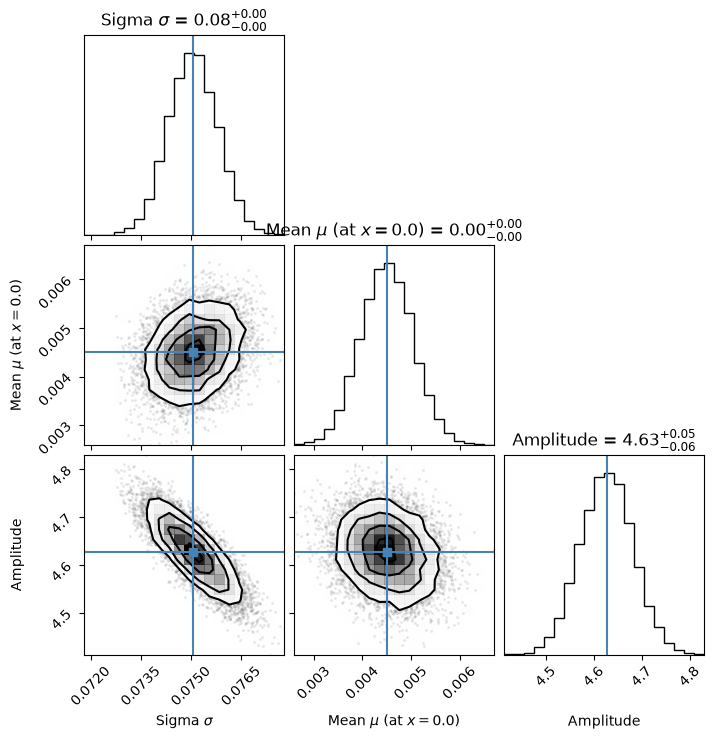

Reduced chi squared = 66.597
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=7.0.h5
Median sigma: 0.075, mean: 0.005, amplitude: 4.627
m bin:  [9.0, 11]
z bin:  [7.5, 8.5]
Number of gals in bin:  10
Guesses: sig = 0.062, mean = 0.002, amplitude = 5.017


100%|██████████| 5000/5000 [00:07<00:00, 714.26it/s]


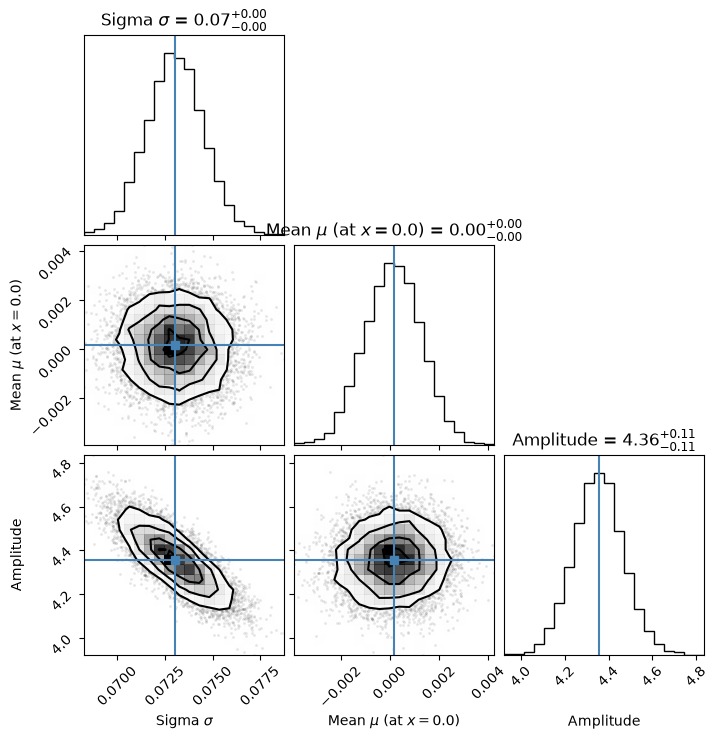

Reduced chi squared = 21.583
Posterior: -1.267 -- 1.098, length = 5000
From fit: mean = 0.000, sigma = 0.073
From hist of posterior: mean = -0.013676374351746734
Tails too long, trimming posterior and refitting.
Posterior: -0.364 -- 0.364, length = 4609
Guesses: sig = 0.060, mean = 0.002, amplitude = 5.613


100%|██████████| 5000/5000 [00:06<00:00, 786.92it/s]


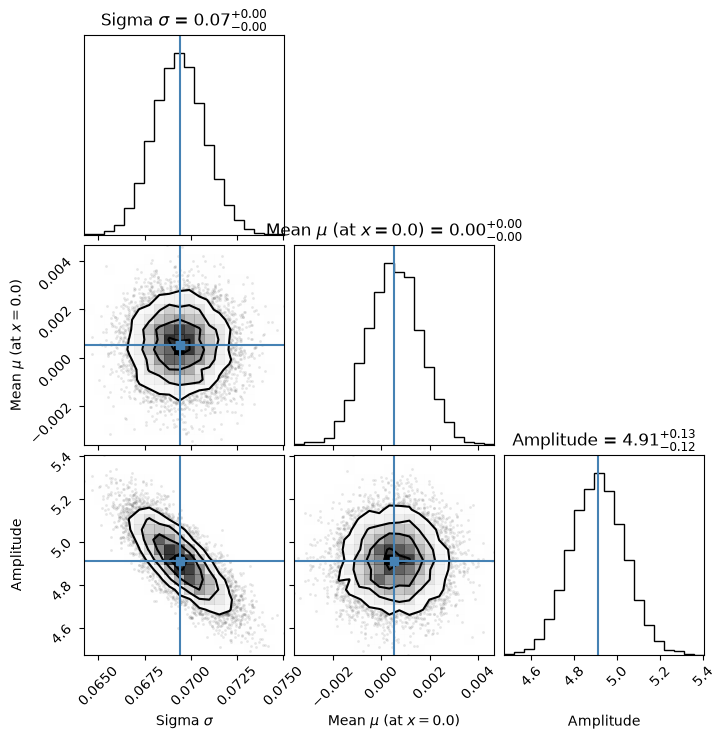

Reduced chi squared = 14.308
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=8.0.h5
Median sigma: 0.069, mean: 0.001, amplitude: 4.910
m bin:  [9.0, 11]
z bin:  [8.5, 9.5]
Number of gals in bin:  6
Guesses: sig = 0.045, mean = 0.002, amplitude = 7.609


100%|██████████| 5000/5000 [00:05<00:00, 845.84it/s]


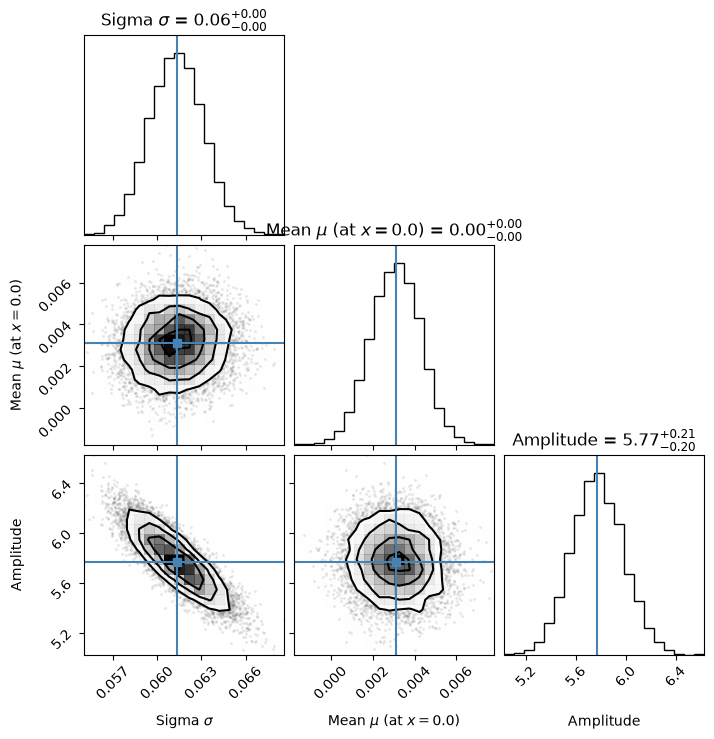

Reduced chi squared = 7.161
Posterior: -1.476 -- 0.429, length = 3000
From fit: mean = 0.003, sigma = 0.061
From hist of posterior: mean = -0.009100745538178523
Tails too long, trimming posterior and refitting.
Posterior: -0.300 -- 0.287, length = 2991
Guesses: sig = 0.042, mean = 0.001, amplitude = 8.010


100%|██████████| 5000/5000 [00:06<00:00, 787.10it/s]


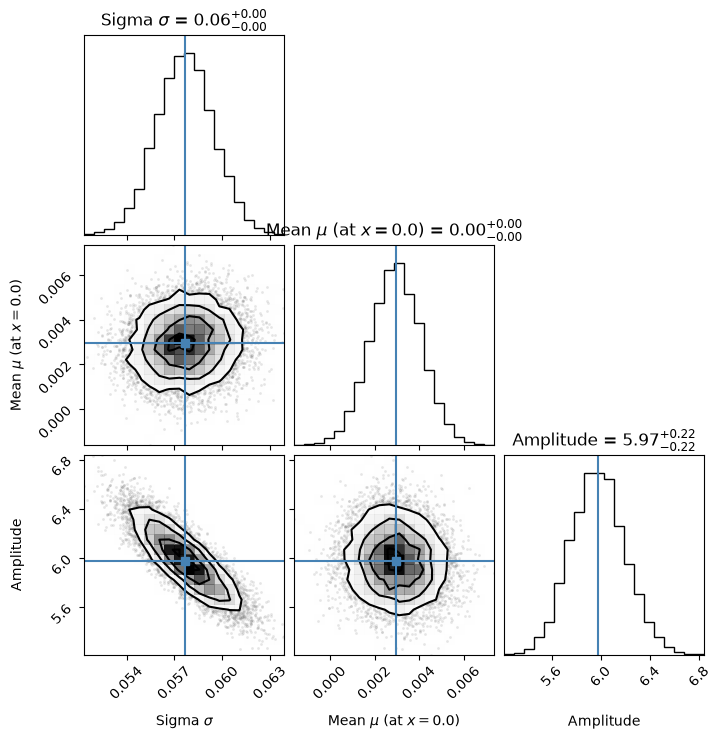

Reduced chi squared = 8.614
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=9.0.h5
Median sigma: 0.058, mean: 0.003, amplitude: 5.975
m bin:  [9.0, 11]
z bin:  [9.5, 10.5]
Number of gals in bin:  5
Guesses: sig = 0.051, mean = 0.007, amplitude = 6.233


100%|██████████| 5000/5000 [00:06<00:00, 817.76it/s]


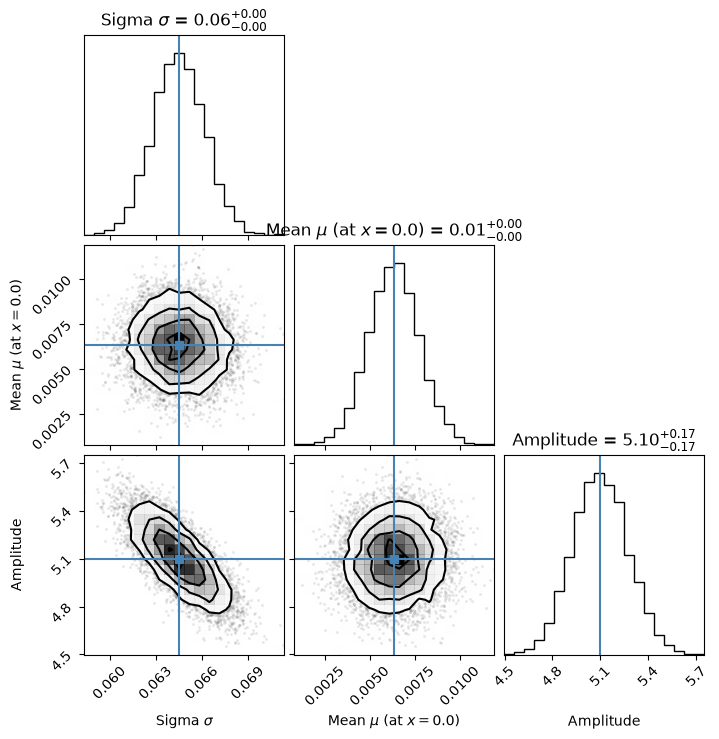

Reduced chi squared = 9.304
Posterior: -1.372 -- 0.492, length = 2500
From fit: mean = 0.006, sigma = 0.065
From hist of posterior: mean = 0.025997496726551383
Tails too long, trimming posterior and refitting.
Posterior: -0.313 -- 0.295, length = 2315
Guesses: sig = 0.047, mean = 0.007, amplitude = 7.180


100%|██████████| 5000/5000 [00:06<00:00, 770.26it/s]


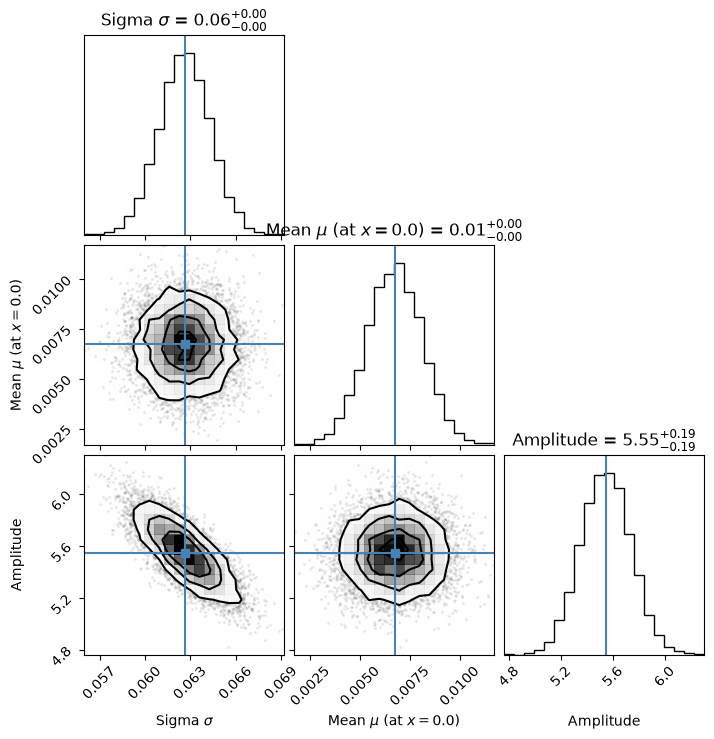

Reduced chi squared = 6.347
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=10.0.h5
Median sigma: 0.063, mean: 0.007, amplitude: 5.546
m bin:  [9.0, 11]
z bin:  [10.5, 11.5]
Number of gals in bin:  14
Guesses: sig = 0.103, mean = 0.013, amplitude = 3.210


100%|██████████| 5000/5000 [00:06<00:00, 741.30it/s]


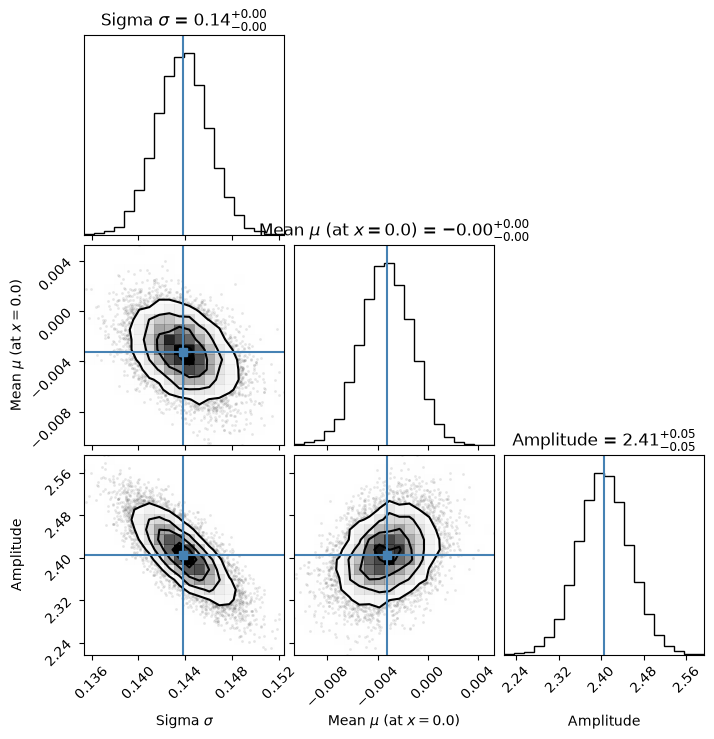

Reduced chi squared = 19.653
Posterior: -3.048 -- 1.282, length = 7000
From fit: mean = -0.003, sigma = 0.144
From hist of posterior: mean = 0.0260504558409691
Tails too long, trimming posterior and refitting.
Posterior: -0.720 -- 0.709, length = 6780
Guesses: sig = 0.097, mean = 0.012, amplitude = 3.462


100%|██████████| 5000/5000 [00:07<00:00, 672.81it/s]


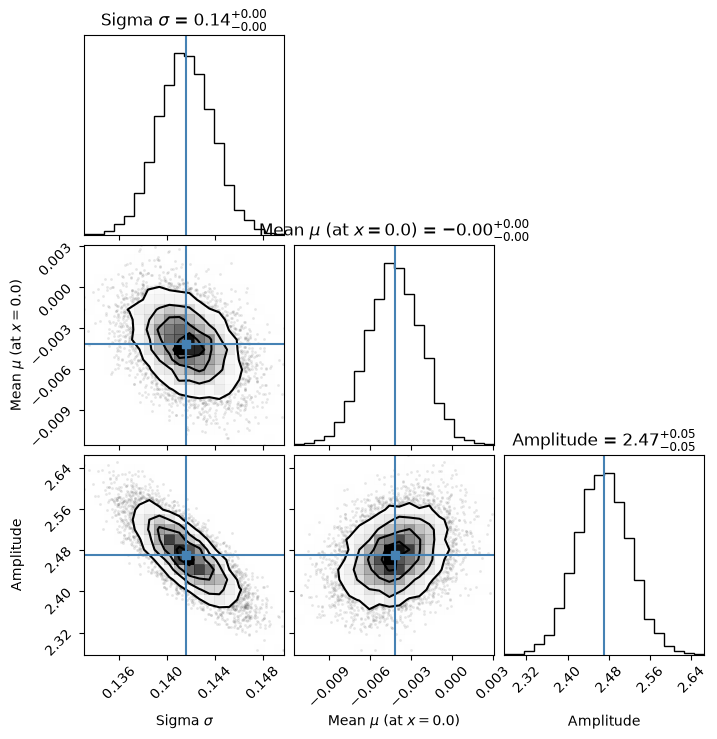

Reduced chi squared = 17.759
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=11.0.h5
Median sigma: 0.142, mean: -0.004, amplitude: 2.470
m bin:  [9.0, 11]
z bin:  [11.5, 13.5]
Number of gals in bin:  15
Guesses: sig = 0.198, mean = 0.038, amplitude = 1.482


100%|██████████| 5000/5000 [00:06<00:00, 726.00it/s]


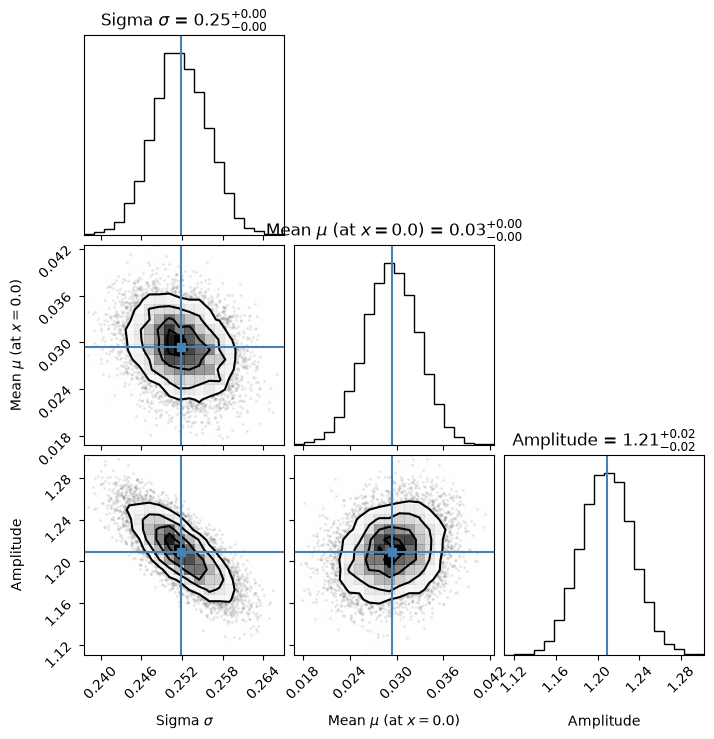

Reduced chi squared = 37.735
Posterior: -6.525 -- 2.969, length = 7500
From fit: mean = 0.029, sigma = 0.252
From hist of posterior: mean = 0.02605473404858971
Tails too long, trimming posterior and refitting.
Posterior: -1.229 -- 1.285, length = 6512
Guesses: sig = 0.182, mean = 0.038, amplitude = 1.815


100%|██████████| 5000/5000 [00:05<00:00, 839.92it/s]


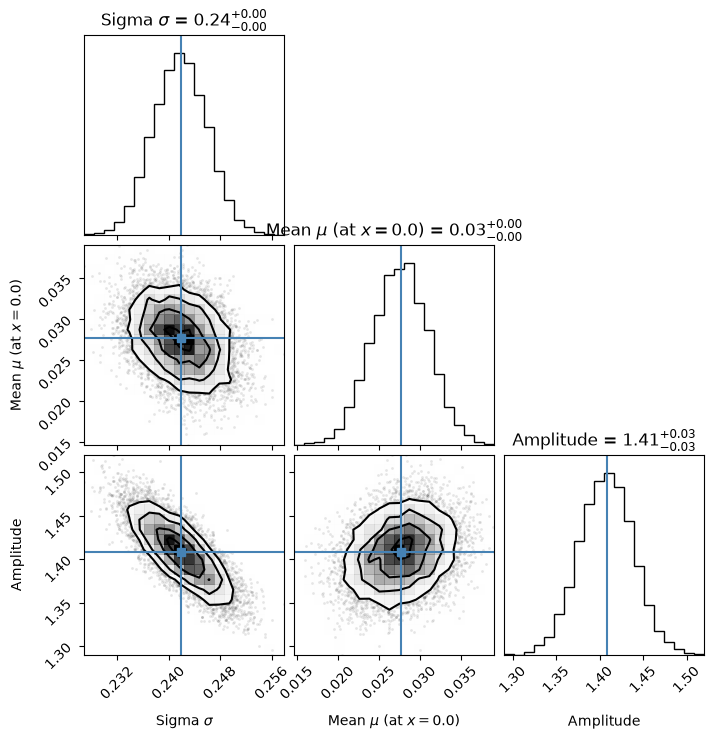

Reduced chi squared = 20.231
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=10.0_z=12.5.h5
Median sigma: 0.242, mean: 0.028, amplitude: 1.408
m bin:  [8, 9.0]
z bin:  [6.5, 7.5]
Number of gals in bin:  314
Guesses: sig = 0.238, mean = -0.021, amplitude = 1.617


100%|██████████| 5000/5000 [00:06<00:00, 770.56it/s]


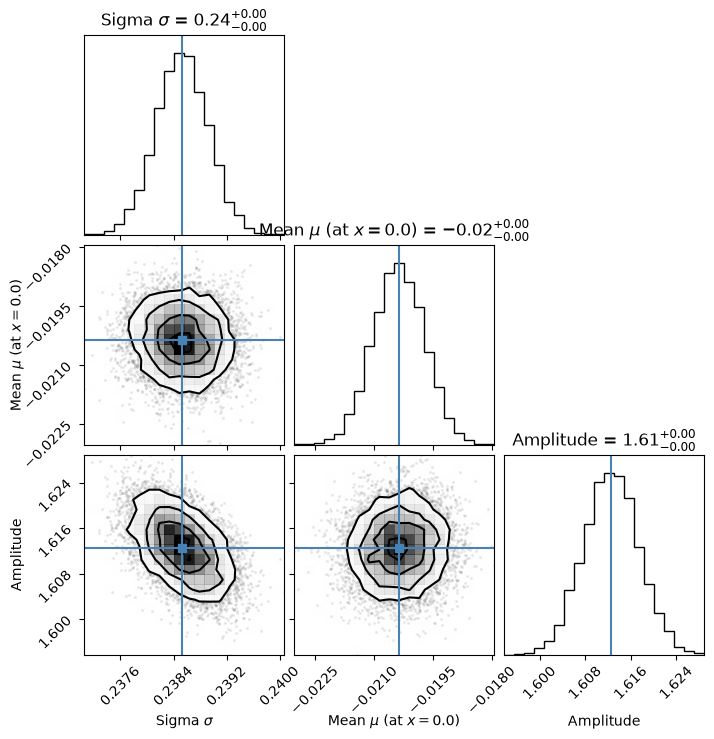

Reduced chi squared = 83.161
Posterior: -9.703 -- 13.832, length = 157000
From fit: mean = -0.020, sigma = 0.239
From hist of posterior: mean = -0.05344709119182145
Tails too long, trimming posterior and refitting.
Posterior: -1.212 -- 1.172, length = 155698
Guesses: sig = 0.132, mean = 0.003, amplitude = 2.591


100%|██████████| 5000/5000 [00:06<00:00, 816.81it/s]


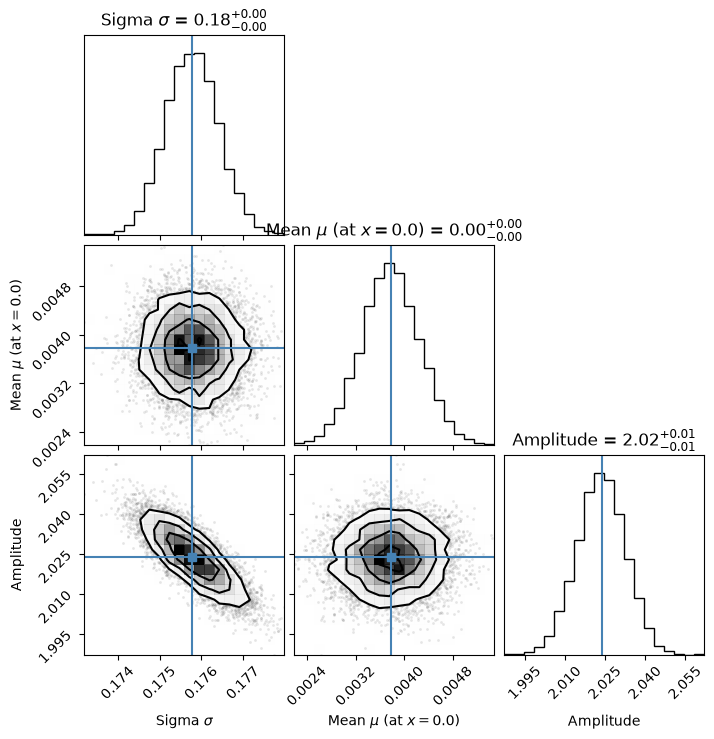

Reduced chi squared = 358.897
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=7.0.h5
Median sigma: 0.176, mean: 0.004, amplitude: 2.024
m bin:  [8, 9.0]
z bin:  [7.5, 8.5]
Number of gals in bin:  137
Guesses: sig = 0.135, mean = 0.003, amplitude = 2.503


100%|██████████| 5000/5000 [00:06<00:00, 827.14it/s]


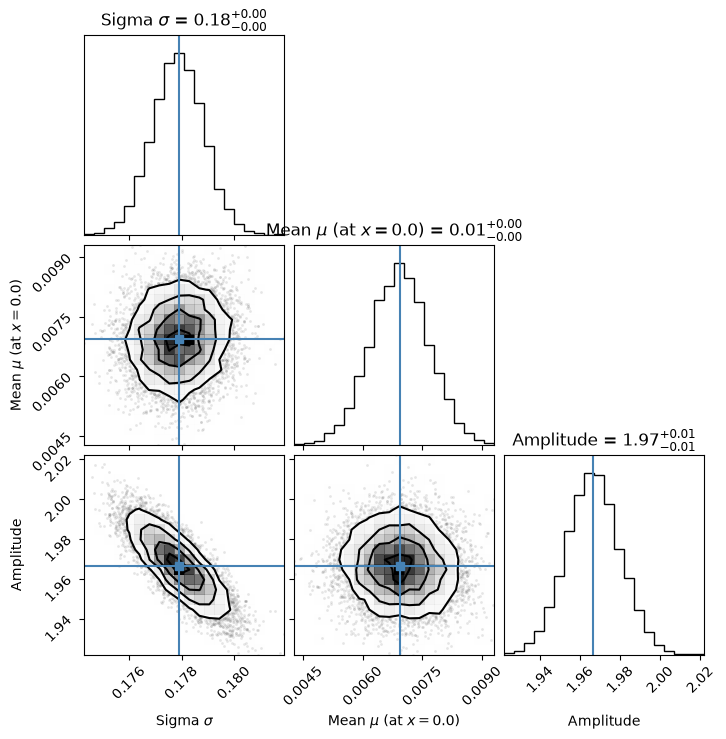

Reduced chi squared = 179.490
Posterior: -2.098 -- 2.082, length = 68500
From fit: mean = 0.007, sigma = 0.178
From hist of posterior: mean = 0.03377355294632922
Tails too long, trimming posterior and refitting.
Posterior: -0.882 -- 0.896, length = 67317
Guesses: sig = 0.130, mean = 0.002, amplitude = 2.606


100%|██████████| 5000/5000 [00:05<00:00, 884.34it/s]


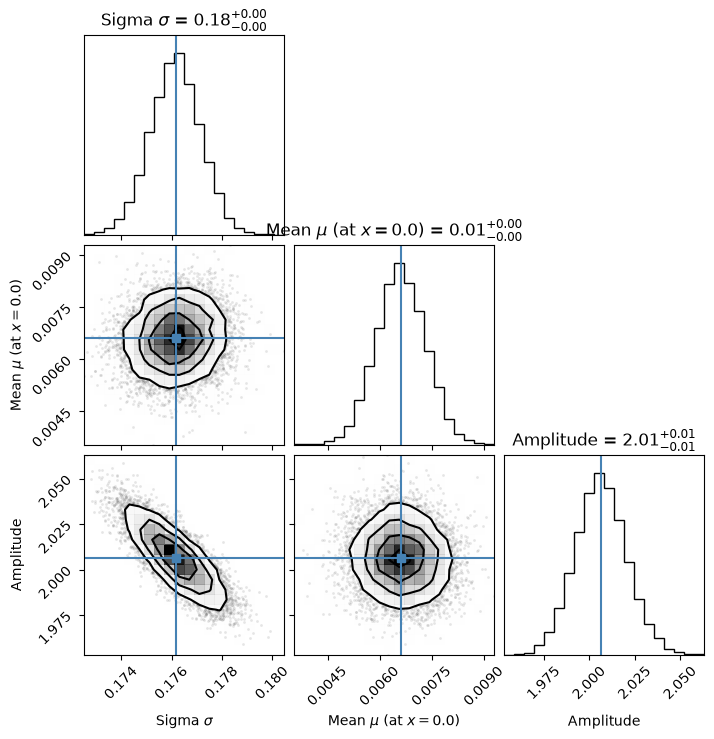

Reduced chi squared = 163.287
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=8.0.h5
Median sigma: 0.176, mean: 0.007, amplitude: 2.006
m bin:  [8, 9.0]
z bin:  [8.5, 9.5]
Number of gals in bin:  47
Guesses: sig = 0.153, mean = 0.005, amplitude = 2.148


100%|██████████| 5000/5000 [00:07<00:00, 708.29it/s]


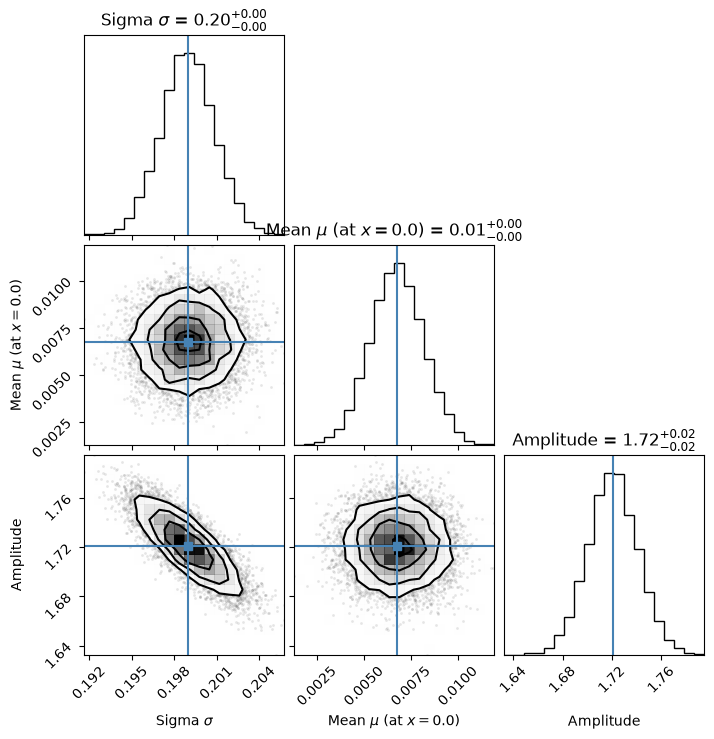

Reduced chi squared = 70.796
Posterior: -1.801 -- 4.930, length = 23500
From fit: mean = 0.007, sigma = 0.199
From hist of posterior: mean = 0.016427005998816857
Tails too long, trimming posterior and refitting.
Posterior: -0.987 -- 1.000, length = 23092
Guesses: sig = 0.144, mean = 0.002, amplitude = 2.297


100%|██████████| 5000/5000 [00:05<00:00, 833.40it/s]


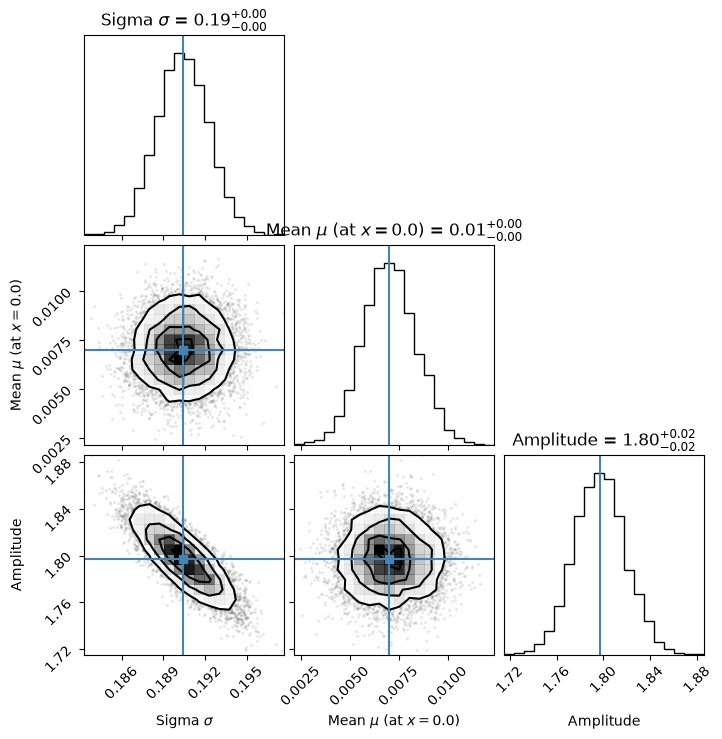

Reduced chi squared = 69.928
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=9.0.h5
Median sigma: 0.190, mean: 0.007, amplitude: 1.797
m bin:  [8, 9.0]
z bin:  [9.5, 10.5]
Number of gals in bin:  47
Guesses: sig = 0.197, mean = 0.017, amplitude = 1.691


100%|██████████| 5000/5000 [00:05<00:00, 855.99it/s]


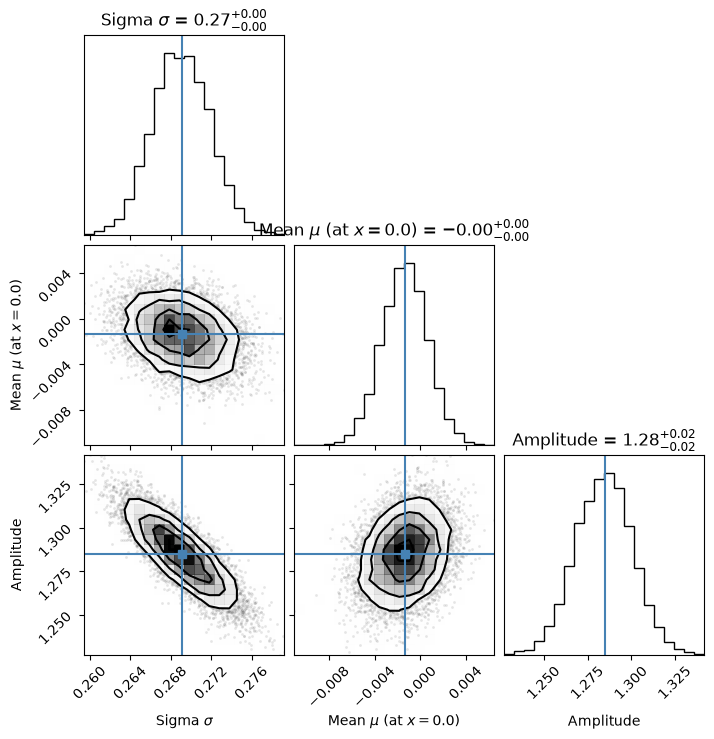

Reduced chi squared = 66.883
Posterior: -2.056 -- 1.993, length = 23500
From fit: mean = -0.001, sigma = 0.269
From hist of posterior: mean = 0.008937172244708691
Tails too long, trimming posterior and refitting.
Posterior: -1.346 -- 1.303, length = 23350
Guesses: sig = 0.194, mean = 0.017, amplitude = 1.719


100%|██████████| 5000/5000 [00:05<00:00, 866.39it/s]


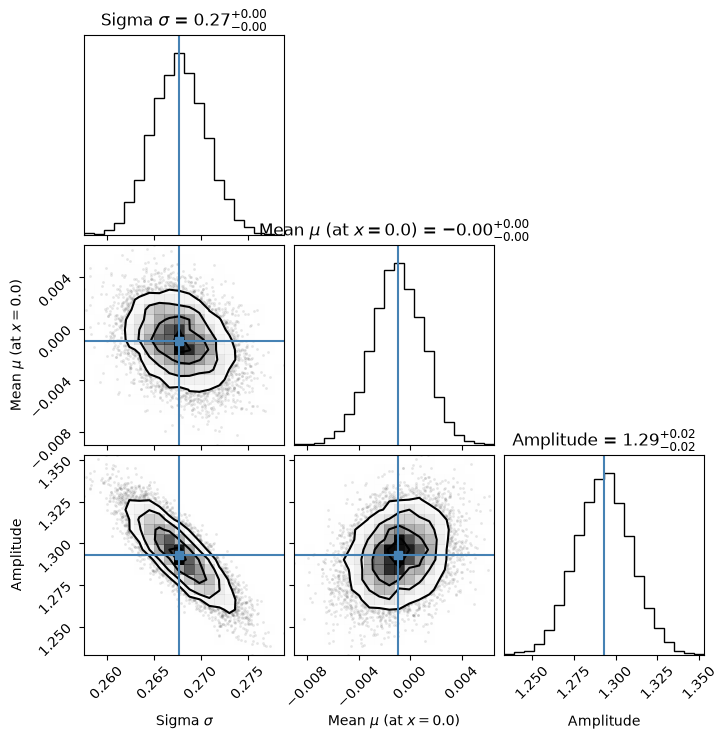

Reduced chi squared = 65.579
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=10.0.h5
Median sigma: 0.268, mean: -0.001, amplitude: 1.293
m bin:  [8, 9.0]
z bin:  [10.5, 11.5]
Number of gals in bin:  45
Guesses: sig = 0.246, mean = 0.047, amplitude = 1.269


100%|██████████| 5000/5000 [00:05<00:00, 858.08it/s]


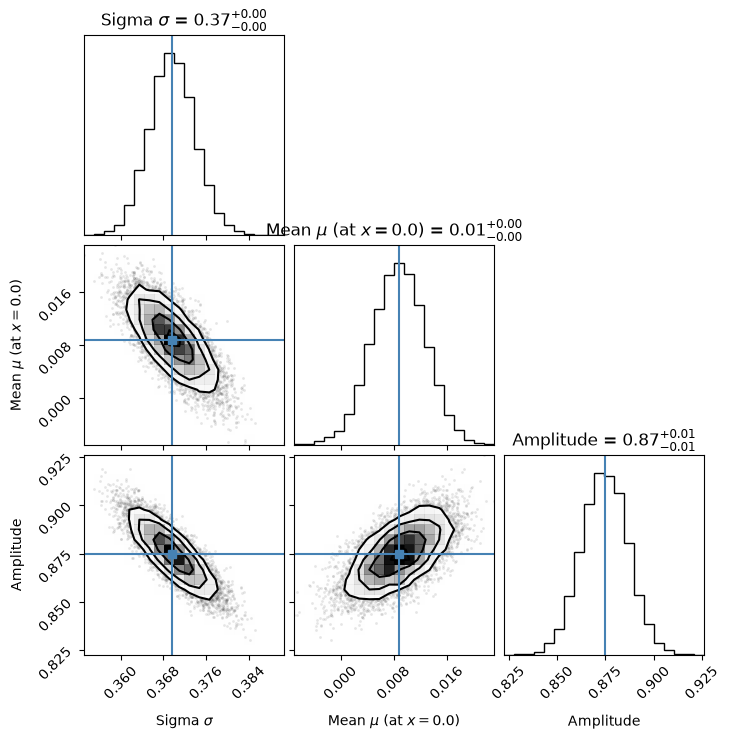

Reduced chi squared = 90.650
Posterior: -2.181 -- 1.427, length = 22500
From fit: mean = 0.009, sigma = 0.370
From hist of posterior: mean = 0.019849735374361188
Tails too long, trimming posterior and refitting.
Posterior: -1.839 -- 1.427, length = 22390
Guesses: sig = 0.245, mean = 0.047, amplitude = 1.279


100%|██████████| 5000/5000 [00:05<00:00, 878.85it/s]


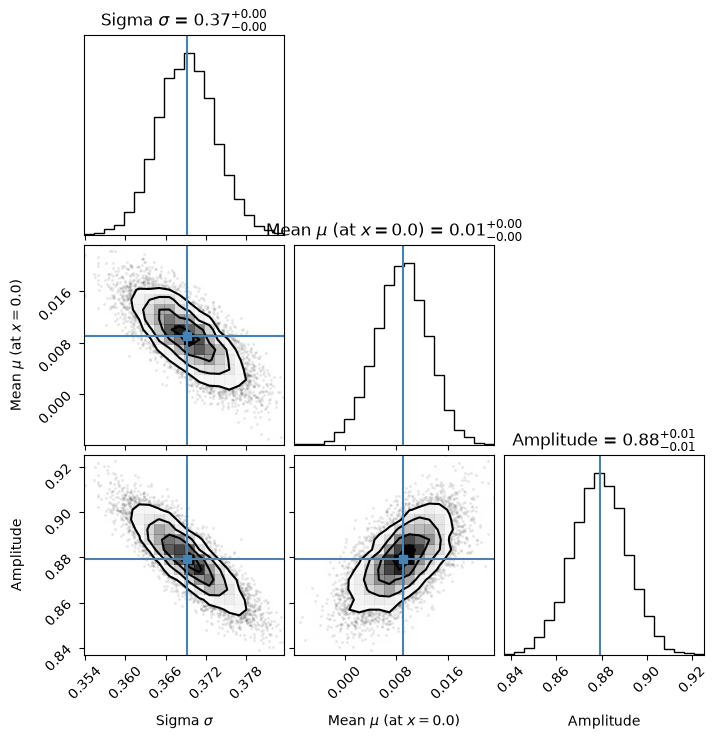

Reduced chi squared = 88.716
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=11.0.h5
Median sigma: 0.369, mean: 0.009, amplitude: 0.879
m bin:  [8, 9.0]
z bin:  [11.5, 13.5]
Number of gals in bin:  42
Guesses: sig = 0.184, mean = 0.035, amplitude = 1.455


100%|██████████| 5000/5000 [00:05<00:00, 974.02it/s]


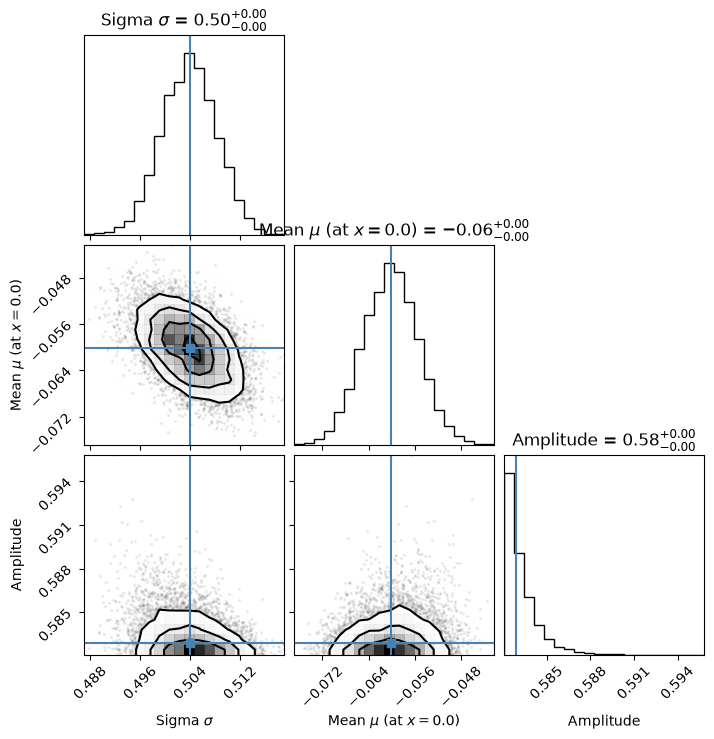

Reduced chi squared = 128.248
Posterior: -3.456 -- 3.706, length = 21000
From fit: mean = -0.060, sigma = 0.504
From hist of posterior: mean = 0.05344066878571074
Tails too long, trimming posterior and refitting.
Posterior: -2.556 -- 2.457, length = 20908
Guesses: sig = 0.176, mean = 0.032, amplitude = 1.503


100%|██████████| 5000/5000 [00:05<00:00, 947.46it/s]


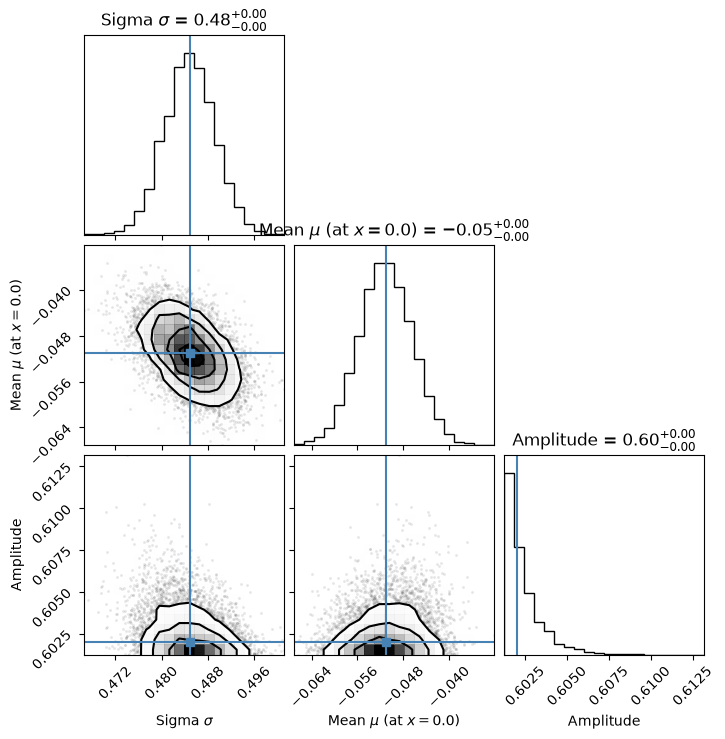

Reduced chi squared = 130.286
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=8.5_z=12.5.h5
Median sigma: 0.485, mean: -0.051, amplitude: 0.602
m bin:  [5, 8]
z bin:  [6.5, 7.5]
Number of gals in bin:  958
Guesses: sig = 0.142, mean = -0.007, amplitude = 2.494


100%|██████████| 5000/5000 [00:06<00:00, 800.33it/s]


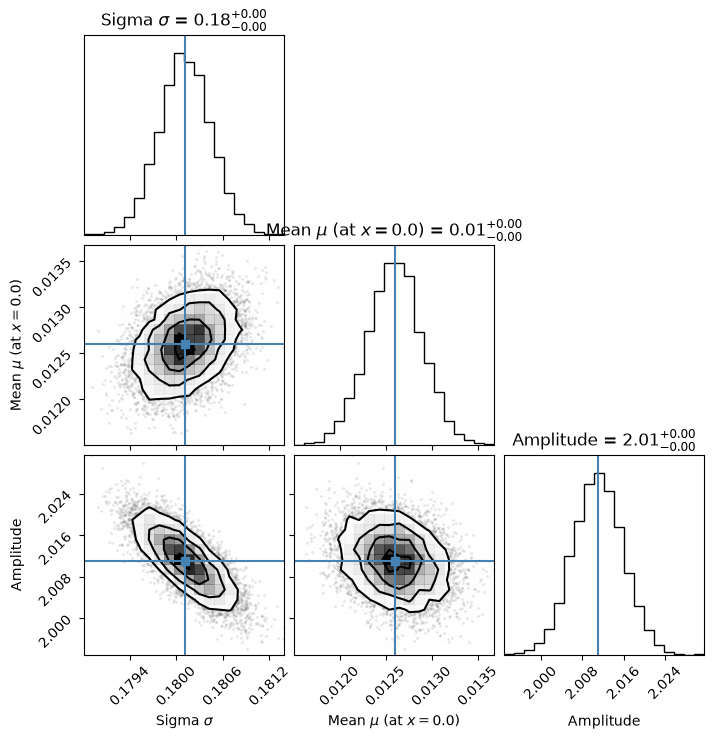

Reduced chi squared = 938.013
Posterior: -2.055 -- 3.330, length = 479000
From fit: mean = 0.013, sigma = 0.180
From hist of posterior: mean = -0.062469881929276605
Tails too long, trimming posterior and refitting.
Posterior: -0.887 -- 0.913, length = 477292
Guesses: sig = 0.133, mean = -0.008, amplitude = 2.618


100%|██████████| 5000/5000 [00:06<00:00, 779.67it/s]


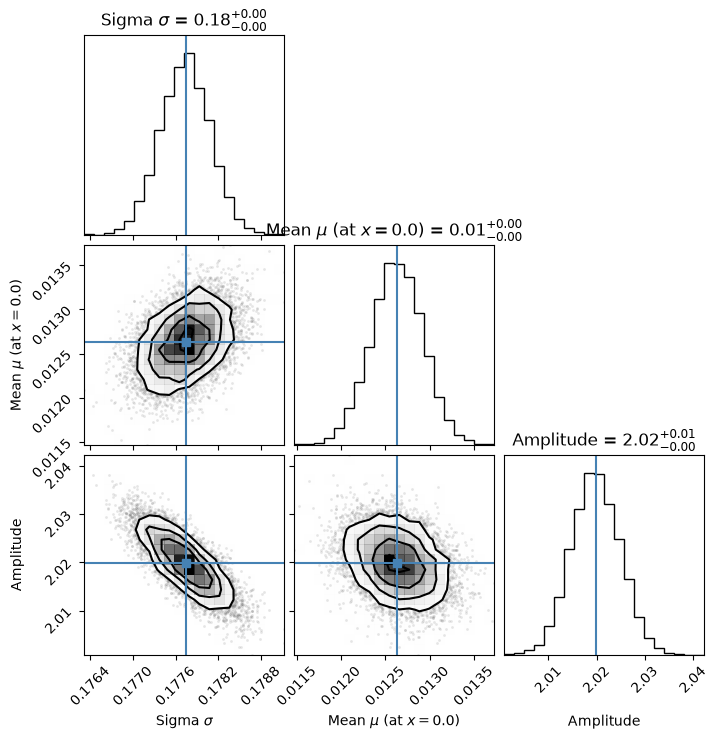

Reduced chi squared = 1016.889
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=7.0.h5
Median sigma: 0.178, mean: 0.013, amplitude: 2.020
m bin:  [5, 8]
z bin:  [7.5, 8.5]
Number of gals in bin:  406
Guesses: sig = 0.145, mean = -0.011, amplitude = 2.346


100%|██████████| 5000/5000 [00:06<00:00, 782.03it/s]


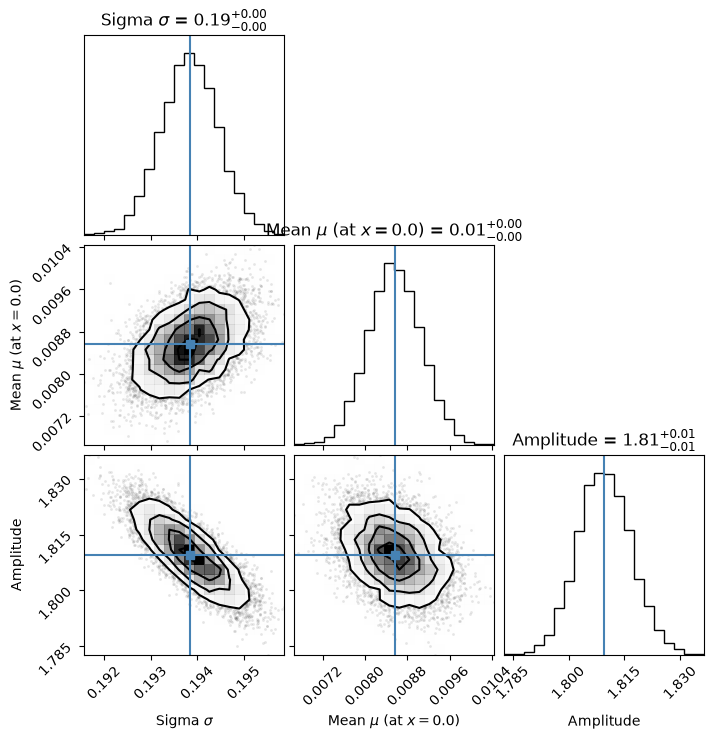

Reduced chi squared = 521.059
Posterior: -1.672 -- 2.609, length = 203000
From fit: mean = 0.009, sigma = 0.194
From hist of posterior: mean = -0.0026394301411722942
Tails too long, trimming posterior and refitting.
Posterior: -0.960 -- 0.978, length = 201780
Guesses: sig = 0.140, mean = -0.013, amplitude = 2.412


100%|██████████| 5000/5000 [00:06<00:00, 804.22it/s]


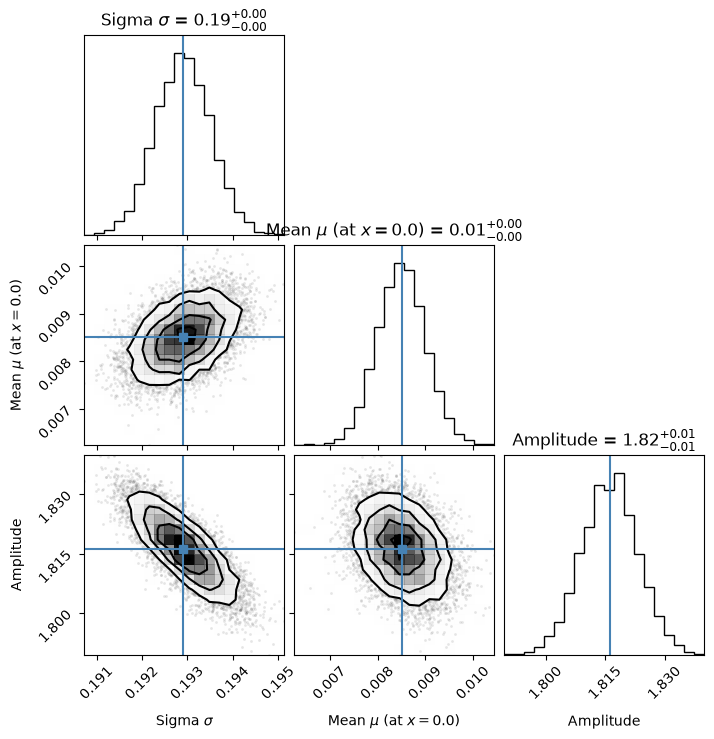

Reduced chi squared = 522.705
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=8.0.h5
Median sigma: 0.193, mean: 0.009, amplitude: 1.816
m bin:  [5, 8]
z bin:  [8.5, 9.5]
Number of gals in bin:  173
Guesses: sig = 0.145, mean = -0.018, amplitude = 2.246


100%|██████████| 5000/5000 [00:06<00:00, 761.51it/s]


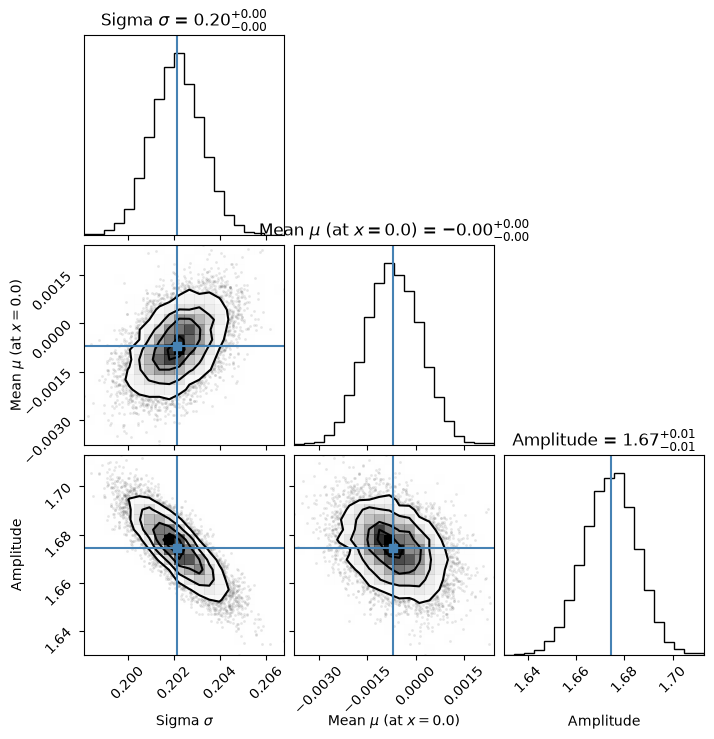

Reduced chi squared = 278.819
Posterior: -1.473 -- 2.702, length = 86500
From fit: mean = -0.001, sigma = 0.202
From hist of posterior: mean = -0.012075941326348483
Tails too long, trimming posterior and refitting.
Posterior: -1.011 -- 1.010, length = 85734
Guesses: sig = 0.142, mean = -0.019, amplitude = 2.298


100%|██████████| 5000/5000 [00:06<00:00, 753.70it/s]


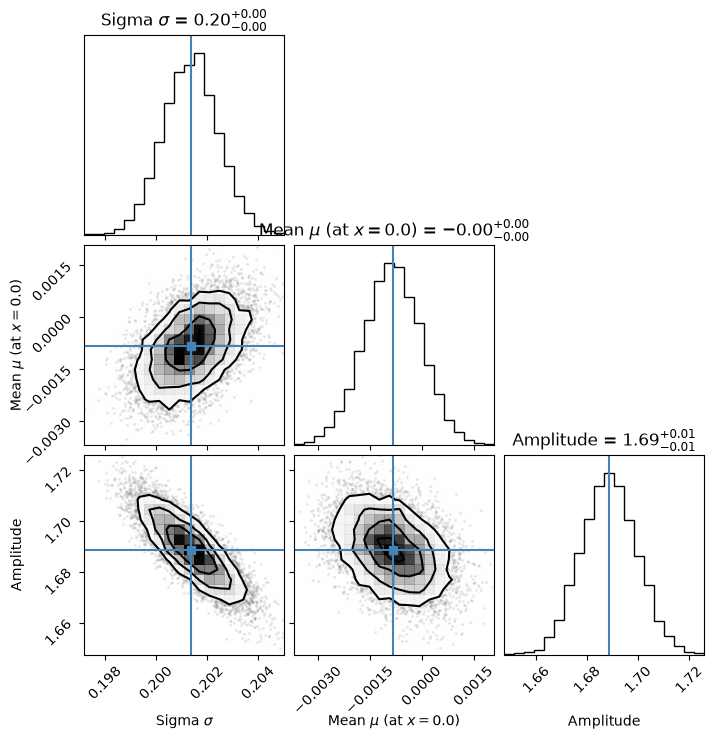

Reduced chi squared = 269.403
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=9.0.h5
Median sigma: 0.201, mean: -0.001, amplitude: 1.689
m bin:  [5, 8]
z bin:  [9.5, 10.5]
Number of gals in bin:  68
Guesses: sig = 0.313, mean = -0.014, amplitude = 1.166


100%|██████████| 5000/5000 [00:05<00:00, 835.58it/s]


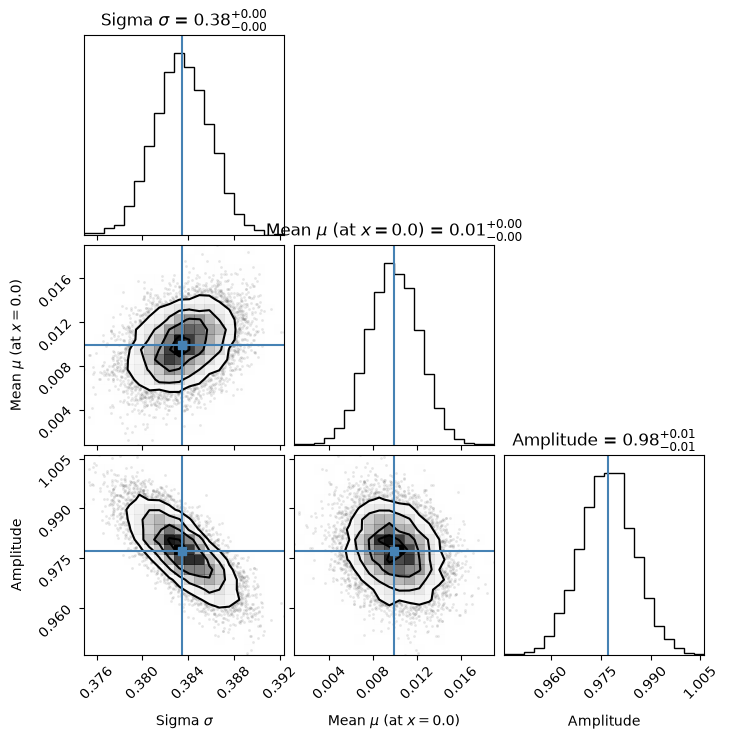

Reduced chi squared = 43.904
Posterior: -1.663 -- 3.064, length = 34000
From fit: mean = 0.010, sigma = 0.383
From hist of posterior: mean = -0.008316221392644985
Tails too long, trimming posterior and refitting.
Posterior: -1.663 -- 1.896, length = 33948
Guesses: sig = 0.312, mean = -0.014, amplitude = 1.172


100%|██████████| 5000/5000 [00:06<00:00, 801.25it/s]


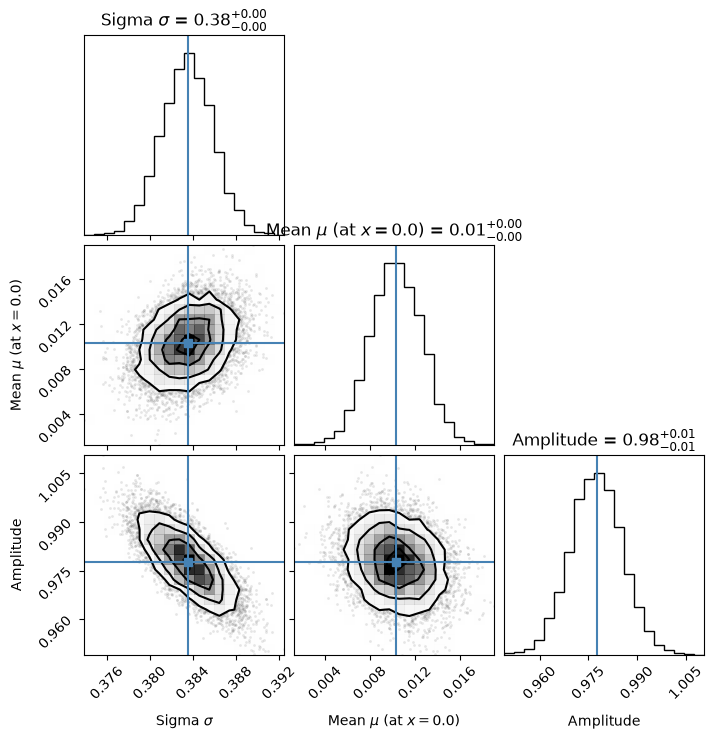

Reduced chi squared = 43.448
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=10.0.h5
Median sigma: 0.384, mean: 0.010, amplitude: 0.978
m bin:  [5, 8]
z bin:  [10.5, 11.5]
Number of gals in bin:  40
Guesses: sig = 0.411, mean = -0.013, amplitude = 0.921


100%|██████████| 5000/5000 [00:05<00:00, 867.24it/s]


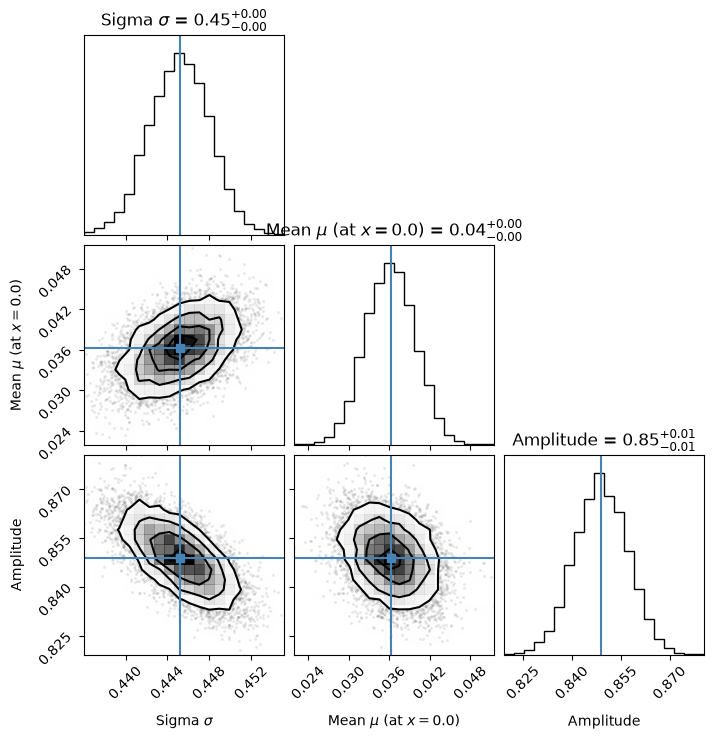

Reduced chi squared = 23.245
Posterior: -1.220 -- 4.014, length = 20000
From fit: mean = 0.036, sigma = 0.445
From hist of posterior: mean = -0.12108070332718734
Tails too long, trimming posterior and refitting.
Posterior: -1.220 -- 2.219, length = 19924
Guesses: sig = 0.410, mean = -0.014, amplitude = 0.928


100%|██████████| 5000/5000 [00:05<00:00, 853.42it/s]


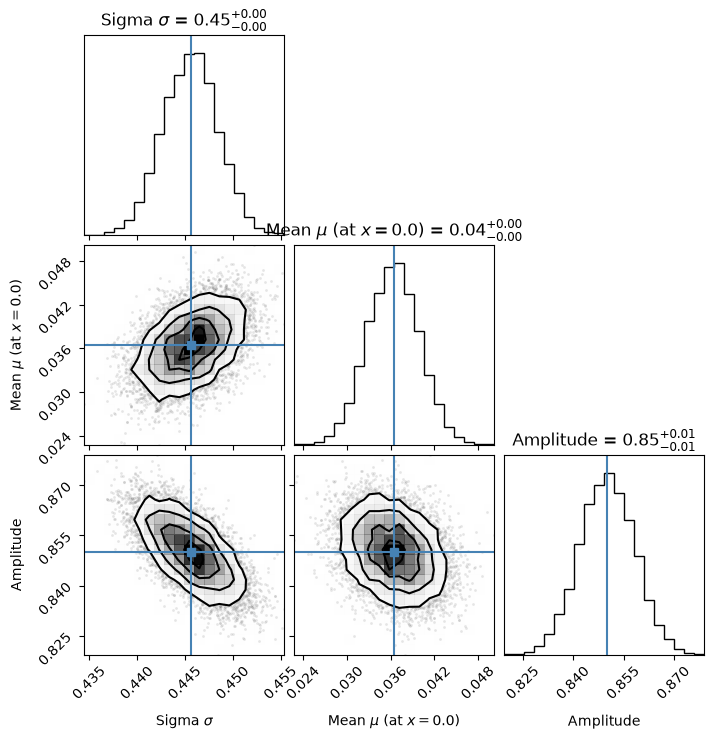

Reduced chi squared = 22.275
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=11.0.h5
Median sigma: 0.446, mean: 0.036, amplitude: 0.850
m bin:  [5, 8]
z bin:  [11.5, 13.5]
Number of gals in bin:  20
Guesses: sig = 0.561, mean = -0.013, amplitude = 0.744


100%|██████████| 5000/5000 [00:05<00:00, 863.56it/s]


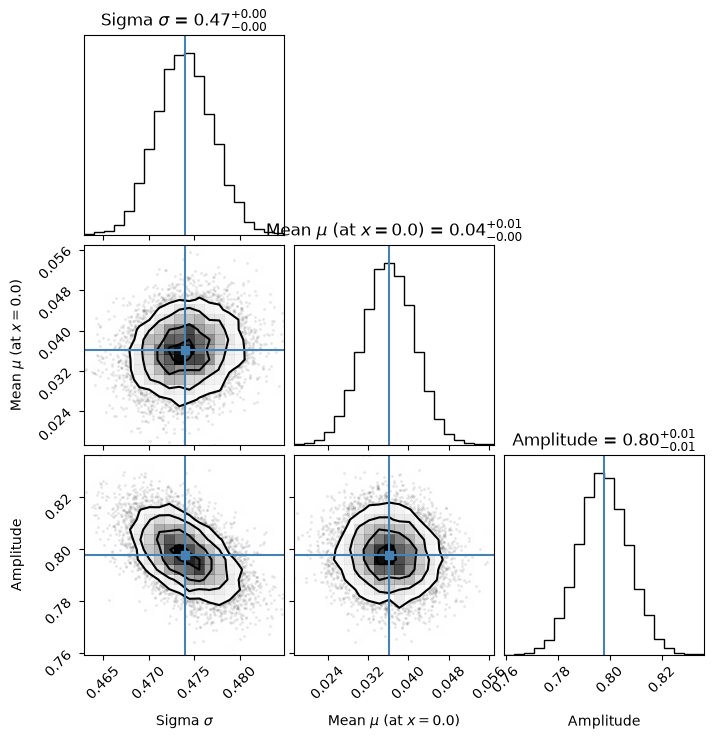

Reduced chi squared = 13.064
Posterior: -1.096 -- 1.436, length = 10000
From fit: mean = 0.036, sigma = 0.474
From hist of posterior: mean = -0.007241913239861342
Saved to /raid/scratch/work/alberttg/Masters_project/Data_products/Gridspec_mass_errors/Gaussian_fit_results/results_table_m=6.5_z=12.5.h5
Median sigma: 0.474, mean: 0.036, amplitude: 0.798


<Figure size 640x480 with 0 Axes>

In [9]:
if __name__ == "__main__":

    with fits.open('/raid/scratch/work/alberttg/Masters_project/Data_products/First_sample_table.fits') as hdu:

        sample_table = hdu[1].data
    sample_table = Table(sample_table)

    SFH_models = ["Bagpipes_sfh_cont_bursty_zEAZYsfhzblueagn_3.0,10.0Myr_Calzetti_log_10_Z_log_10_BPASS_zfix"]

    get_posterior(sample_table, SFH_models[0], refit=True)